# Weather Prediction using Machine Learning
**Dataset adapté : Visual Crossing Weather Data (Ouagadougou)**

In [2]:
!pip install scikit-learn-intelex feature_engine imbalanced-learn xgboost lightgbm catboost --quiet

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings, gc, joblib
warnings.filterwarnings('ignore')

# Accélération Intel optionnelle (ignorée si non disponible)
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ModuleNotFoundError:
    pass

from sklearn.model_selection import (train_test_split, RandomizedSearchCV,
                                      cross_val_score, KFold, GridSearchCV, RepeatedKFold)
from sklearn.linear_model import LogisticRegression, SGDClassifier, PassiveAggressiveClassifier, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC, NuSVC
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier, AdaBoostClassifier,
                               GradientBoostingClassifier, HistGradientBoostingClassifier,
                               VotingClassifier, ExtraTreesClassifier, StackingClassifier)
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier, XGBRFClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                              accuracy_score, precision_score, recall_score, f1_score)
from scipy.stats import probplot
from feature_engine.selection import DropConstantFeatures, DropDuplicateFeatures, DropCorrelatedFeatures
from imblearn.over_sampling import BorderlineSMOTE
from collections import Counter
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, SelectPercentile, SelectFromModel, f_classif

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

## Chargement des données

In [4]:
# Chargement et concaténation des fichiers CSV
# import glob, os

# csv_files = sorted(glob.glob('data-*.csv'))
# if csv_files:
#     df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
#     print(f"Fichiers chargés : {csv_files}")
# else:
#     # Chargement d'un fichier unique si besoin
#     df = pd.read_csv('weather_data.csv')
#     print("Fichier unique chargé.")


data_01 = pd.read_csv('data-01.csv')
data_02 = pd.read_csv('data-02.csv')
data_03 = pd.read_csv('data-03.csv')
data_04 = pd.read_csv('data-04.csv')
data_05 = pd.read_csv('data-05.csv')

# Concaténation en un seul DataFrame
df = pd.concat([data_01, data_02, data_03, data_04, data_05], ignore_index=True)

df.head()

,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
0,Ouagadougou,2015-01-01,86.0,60.2,72.7,82.7,60.2,71.9,22.7,16.3,...,21.4,9.0,NaN,2015-01-01T06:27:13,2015-01-01T17:51:56,0.37,Partially cloudy,Clearing in the afternoon.,partly-cloudy-day,"65503099999,DFFD"
1,Ouagadougou,2015-01-02,86.0,65.9,74.4,82.6,65.9,73.6,25.4,16.3,...,19.9,8.0,NaN,2015-01-02T06:27:36,2015-01-02T17:52:29,0.40,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
2,Ouagadougou,2015-01-03,86.0,62.6,73.9,82.6,62.6,73.2,23.3,15.6,...,20.5,8.0,NaN,2015-01-03T06:27:58,2015-01-03T17:53:03,0.44,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
3,Ouagadougou,2015-01-04,82.8,62.6,72.8,80.2,62.6,72.3,23.5,16.0,...,20.5,8.0,NaN,2015-01-04T06:28:19,2015-01-04T17:53:36,0.48,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"
4,Ouagadougou,2015-01-05,84.3,59.0,71.9,81.3,59.0,71.4,25.8,18.4,...,21.1,9.0,NaN,2015-01-05T06:28:40,2015-01-05T17:54:10,0.50,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"


In [6]:
df.shape

(3658, 33)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3658 entries, 0 to 3657
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              3658 non-null   object 
 1   datetime          3658 non-null   object 
 2   tempmax           3658 non-null   float64
 3   tempmin           3658 non-null   float64
 4   temp              3658 non-null   float64
 5   feelslikemax      3658 non-null   float64
 6   feelslikemin      3658 non-null   float64
 7   feelslike         3658 non-null   float64
 8   dew               3658 non-null   float64
 9   humidity          3658 non-null   float64
 10  precip            3658 non-null   float64
 11  precipprob        3658 non-null   int64  
 12  precipcover       3658 non-null   float64
 13  preciptype        834 non-null    object 
 14  snow              3657 non-null   float64
 15  snowdepth         3657 non-null   float64
 16  windgust          3657 non-null   float64


In [8]:
df.describe()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,precip,precipprob,...,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,severerisk,moonphase
count,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,...,3658.000000,3658.000000,3658.00000,3658.000000,3653.000000,3656.000000,3656.000000,3656.000000,732.000000,3658.000000
mean,95.211372,73.729634,84.162712,97.514817,74.207162,85.690022,56.978814,48.123948,0.099000,21.377802,...,13.374850,152.867059,1011.47515,52.214516,5.635751,252.792916,21.830060,8.772702,18.435792,0.483939
std,6.319792,6.699716,5.631461,7.503230,7.538195,7.132335,17.561488,24.851804,0.366466,41.002797,...,4.834356,86.479804,2.05937,19.061341,1.017553,39.330244,3.400965,1.207378,12.912628,0.288734
min,74.800000,55.400000,67.900000,74.800000,55.400000,67.900000,13.600000,7.500000,0.000000,0.000000,...,4.700000,0.200000,1004.90000,0.000000,1.400000,27.000000,2.200000,1.000000,10.000000,0.000000
25%,90.200000,69.600000,80.000000,92.100000,69.600000,80.000000,39.400000,24.900000,0.000000,0.000000,...,10.300000,63.825000,1010.10000,36.800000,5.300000,239.700000,20.700000,8.000000,10.000000,0.250000
50%,95.000000,74.050000,83.600000,97.800000,74.050000,85.500000,65.900000,45.700000,0.000000,0.000000,...,12.800000,181.200000,1011.60000,49.700000,5.900000,258.000000,22.300000,9.000000,10.000000,0.500000
75%,100.300000,78.300000,88.100000,103.100000,78.300000,90.600000,72.700000,72.300000,0.000000,0.000000,...,15.100000,223.600000,1012.90000,66.075000,6.200000,279.000000,24.100000,9.000000,30.000000,0.750000
max,110.400000,90.400000,99.300000,123.000000,98.900000,105.900000,77.700000,97.800000,5.984000,100.000000,...,92.200000,360.000000,1018.70000,94.600000,15.000000,333.600000,28.900000,10.000000,75.000000,0.980000


In [9]:
df.isna().sum()

,0
name,0
datetime,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
dew,0
humidity,0


In [10]:
df.duplicated().sum()

np.int64(3)

## Exploratory Data Analysis

Skewness de tempmax: -0.0104
Kurtosis de tempmax: -0.6793


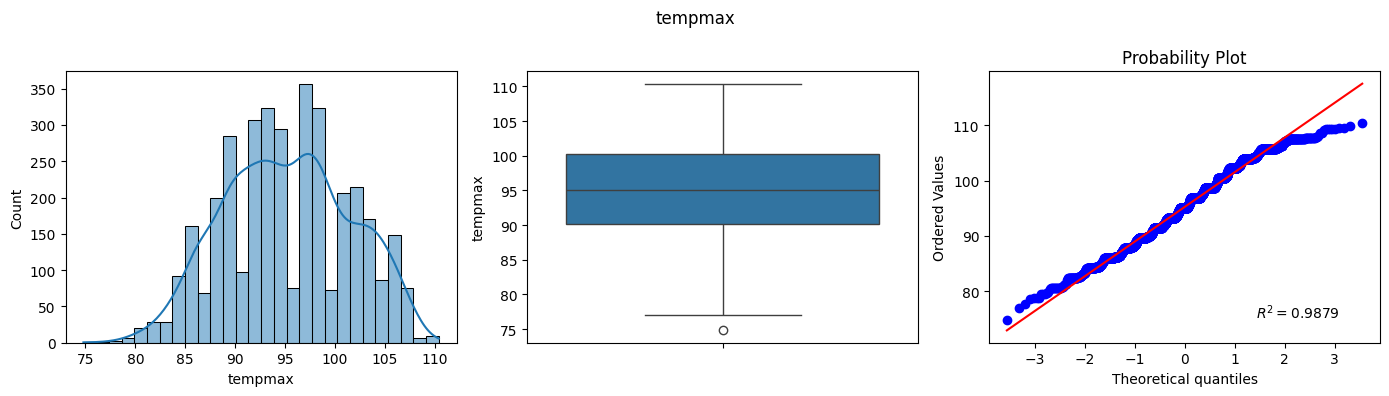

Skewness de tempmin: -0.1068
Kurtosis de tempmin: -0.4948


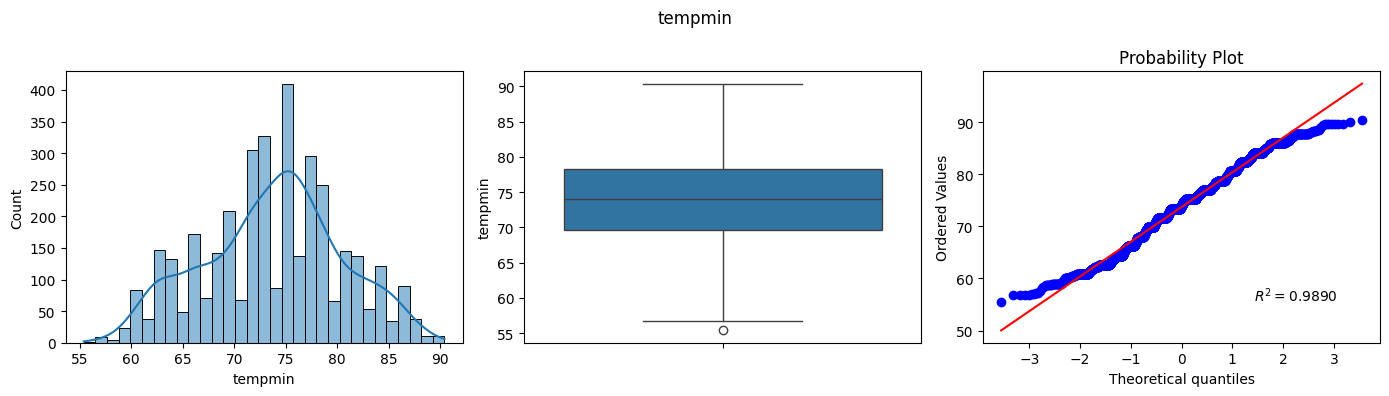

Skewness de temp: 0.2583
Kurtosis de temp: -0.6315


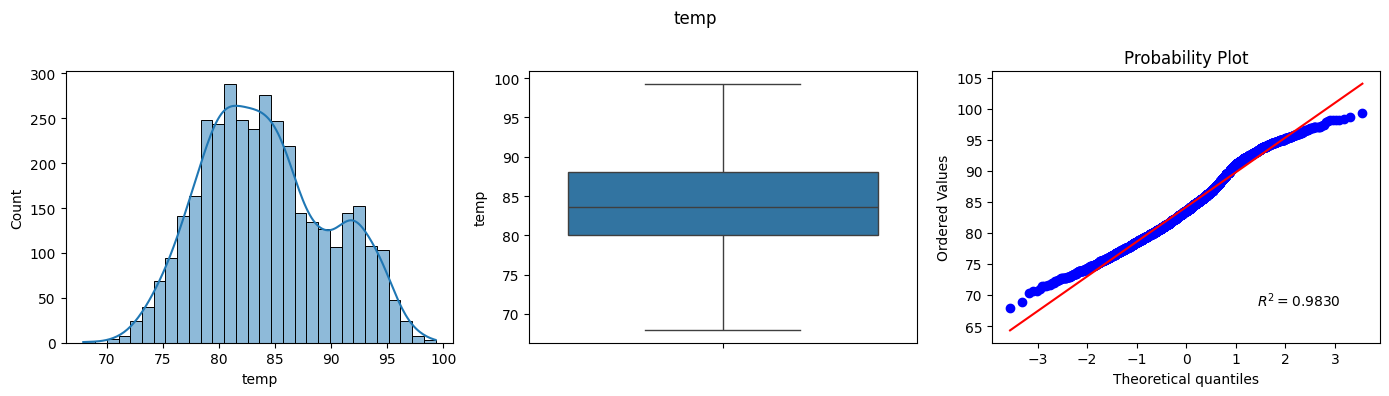

Skewness de feelslikemax: -0.0378
Kurtosis de feelslikemax: -0.5558


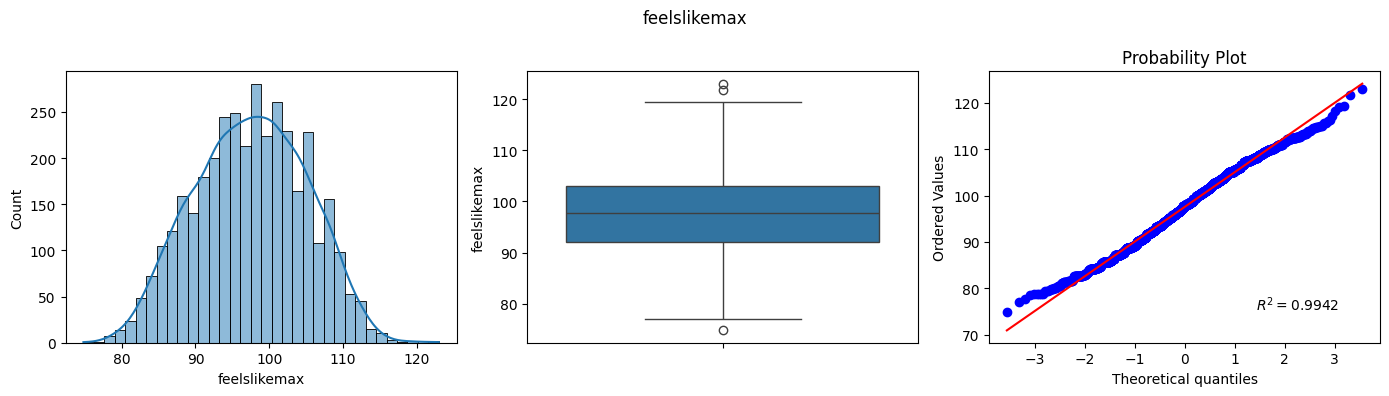

Skewness de feelslikemin: 0.3062
Kurtosis de feelslikemin: -0.1093


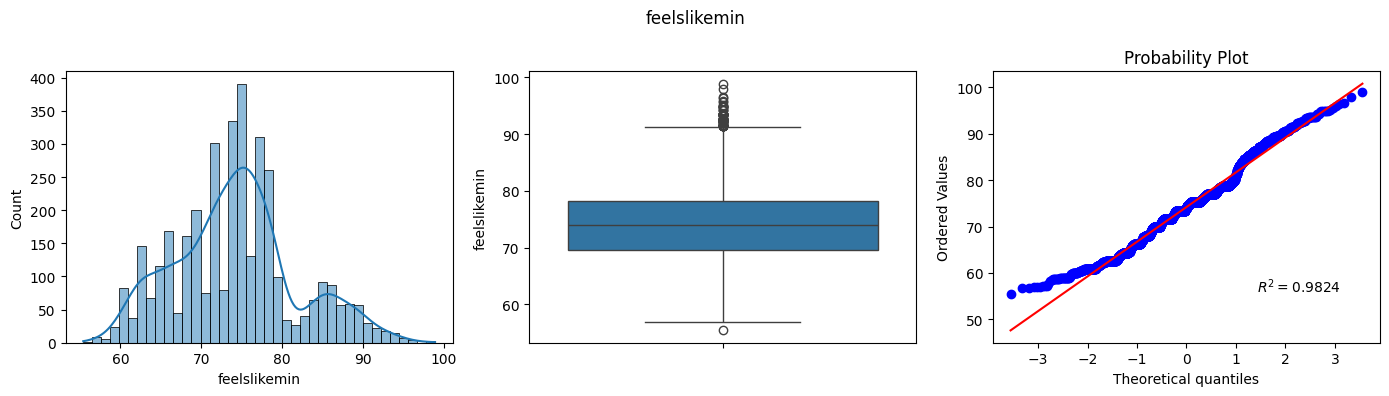

Skewness de feelslike: 0.2193
Kurtosis de feelslike: -0.6356


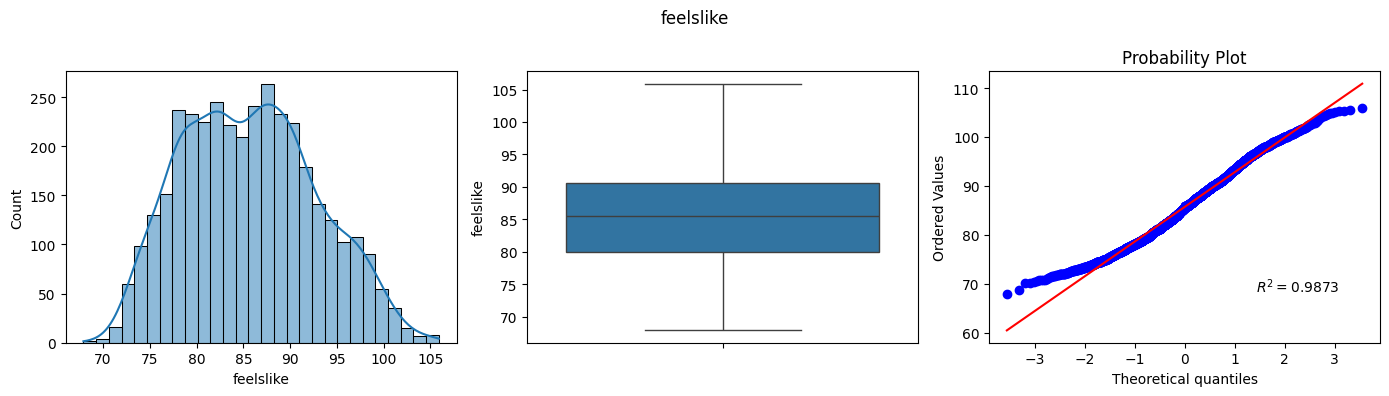

Skewness de dew: -0.5280
Kurtosis de dew: -1.3004


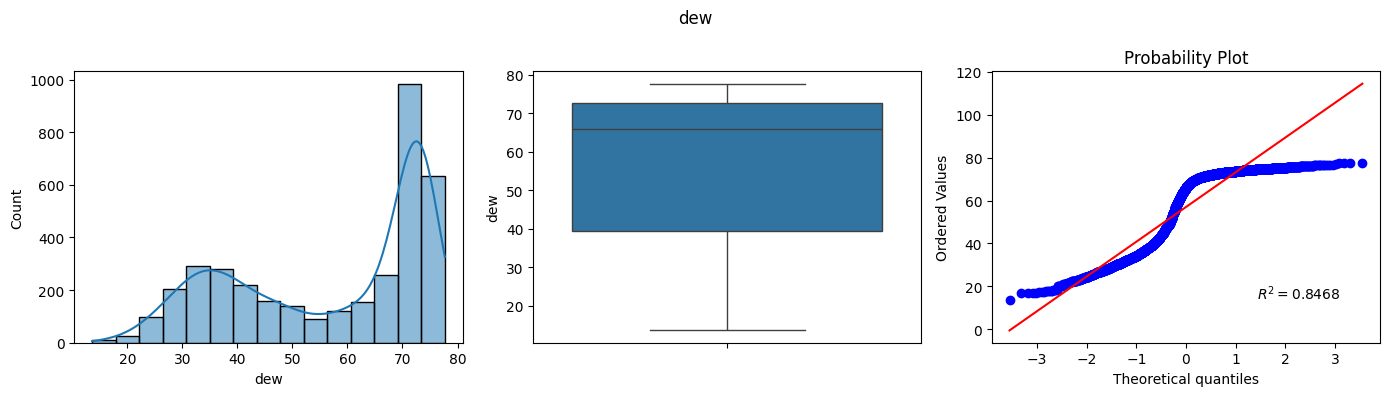

Skewness de humidity: 0.1519
Kurtosis de humidity: -1.4096


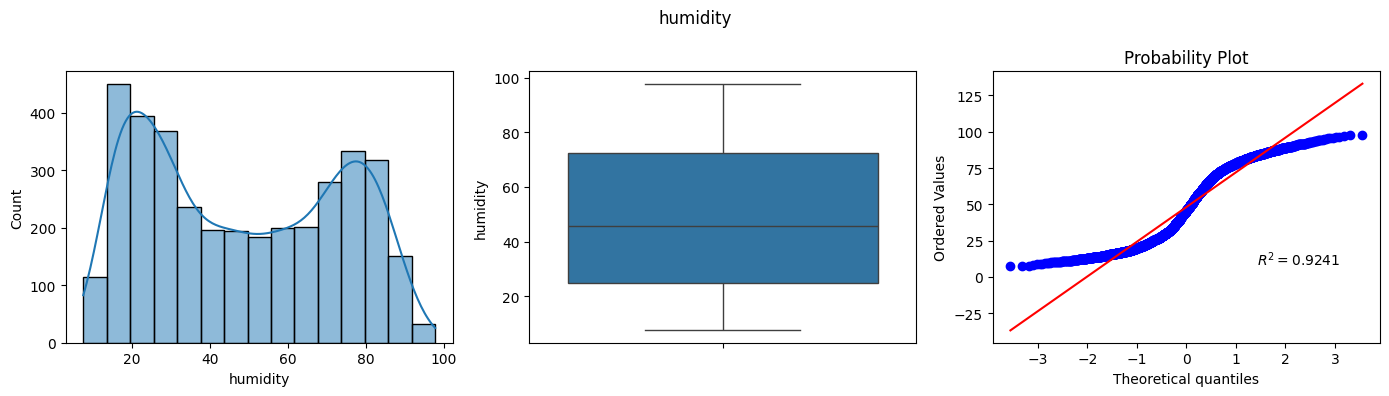

Skewness de precip: 5.8838
Kurtosis de precip: 47.3927


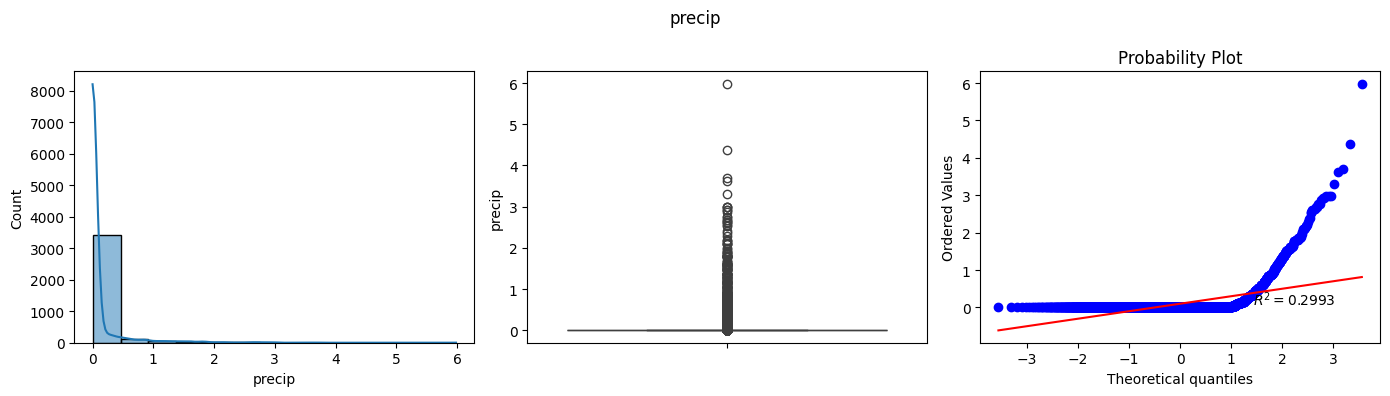

Skewness de precipprob: 1.3969
Kurtosis de precipprob: -0.0488


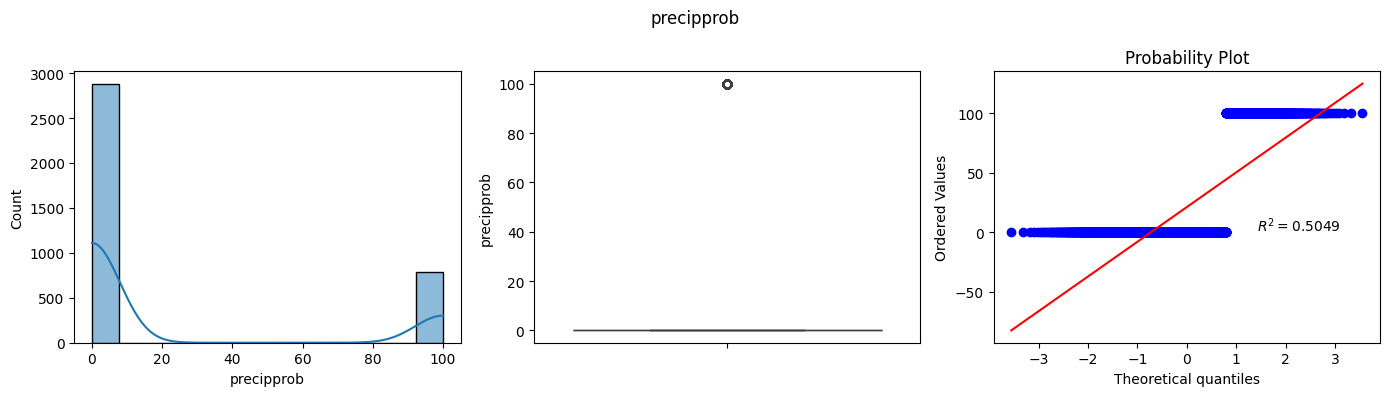

Skewness de precipcover: 7.0213
Kurtosis de precipcover: 103.0584


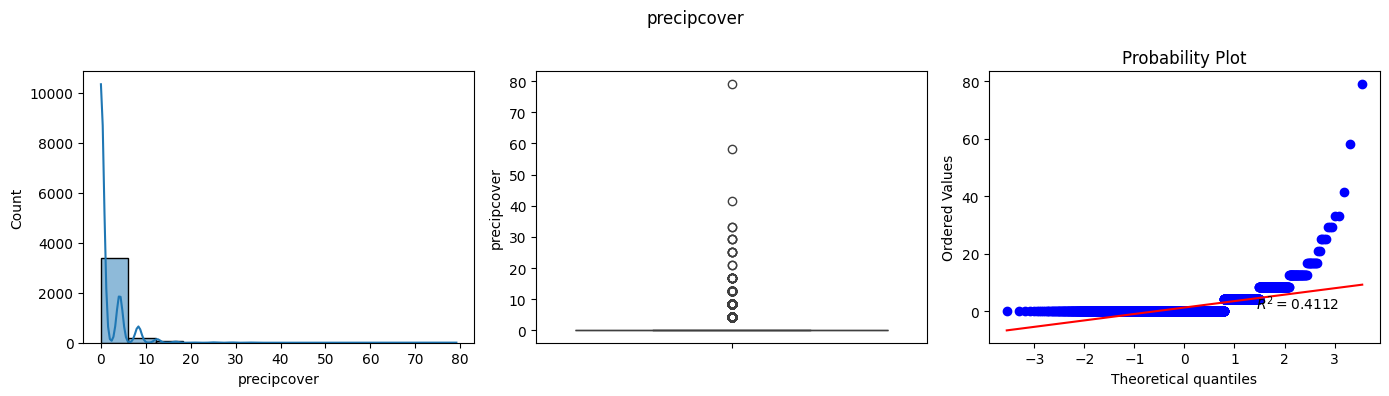

Skewness de snow: 0.0000
Kurtosis de snow: 0.0000


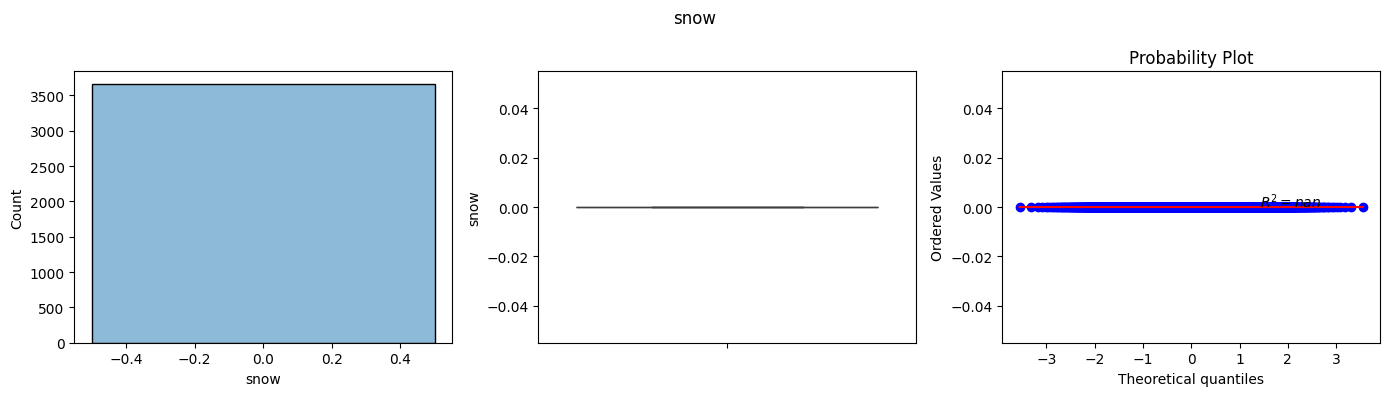

Skewness de snowdepth: 0.0000
Kurtosis de snowdepth: 0.0000


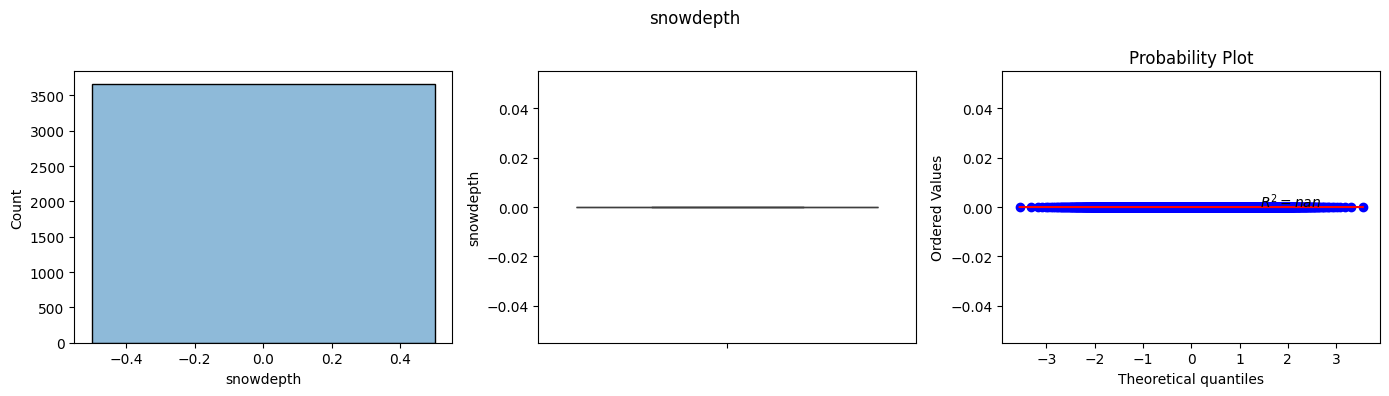

Skewness de windgust: 6.3590
Kurtosis de windgust: 123.6741


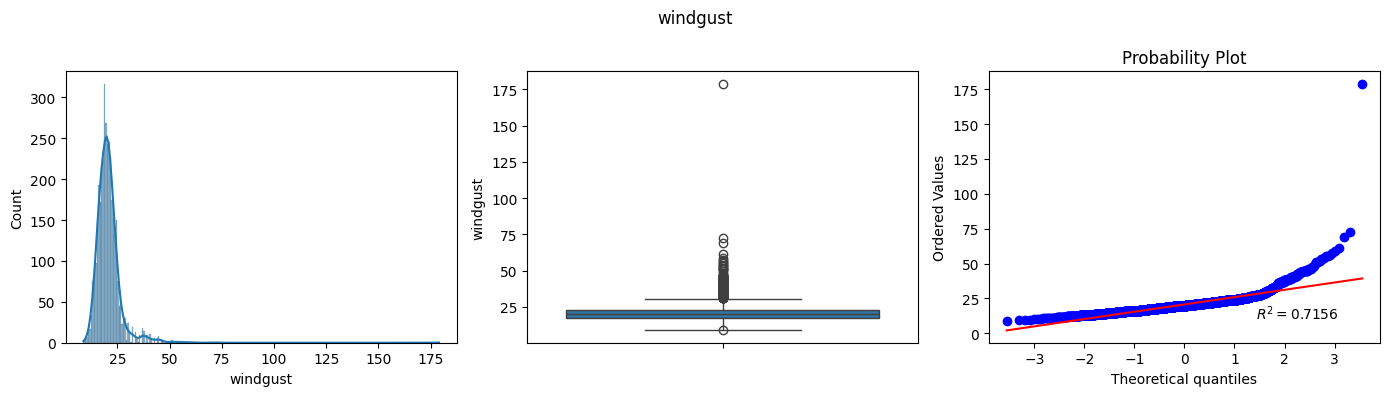

Skewness de windspeed: 3.7992
Kurtosis de windspeed: 44.6678


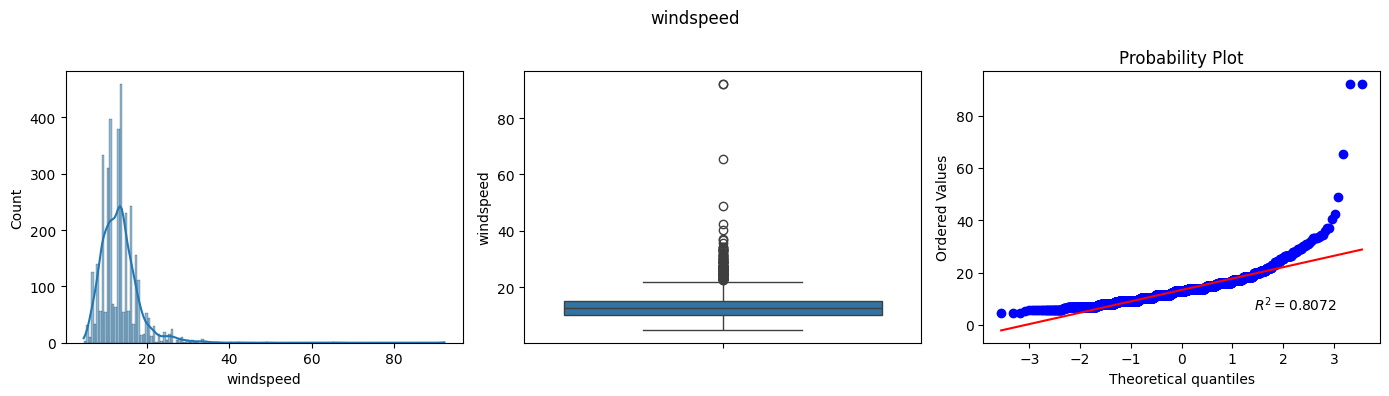

Skewness de winddir: -0.0607
Kurtosis de winddir: -1.2696


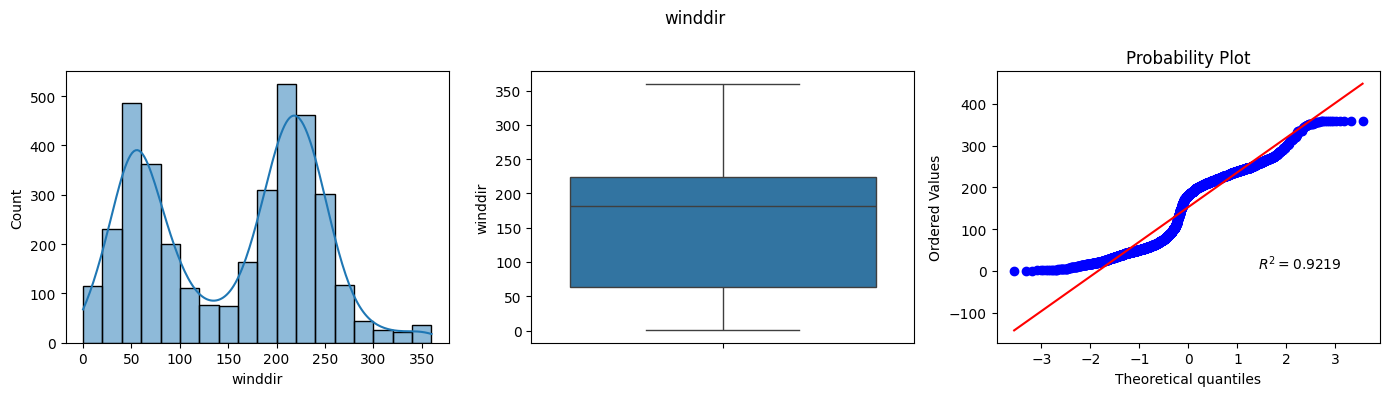

Skewness de sealevelpressure: -0.0983
Kurtosis de sealevelpressure: 0.0213


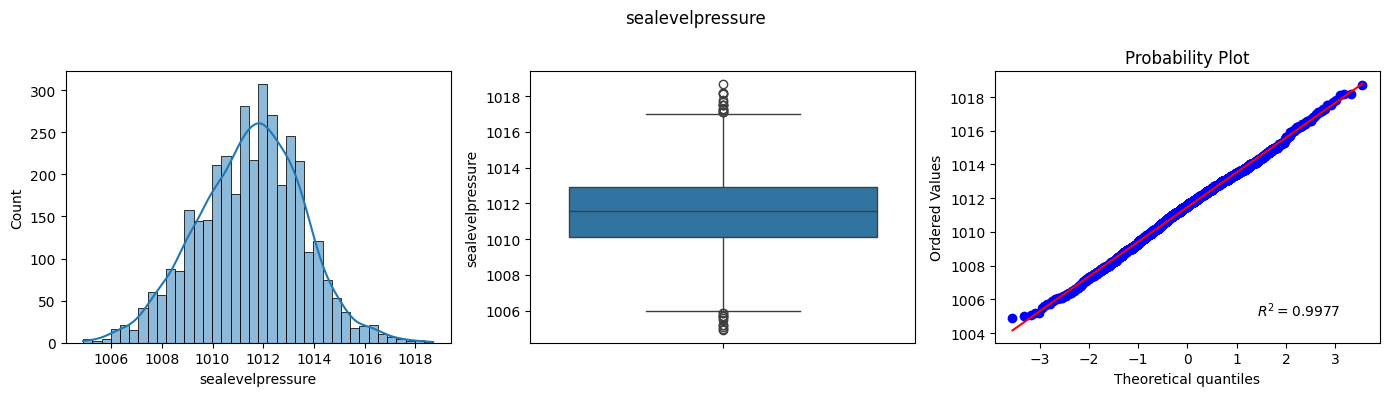

Skewness de cloudcover: 0.3158
Kurtosis de cloudcover: -0.7429


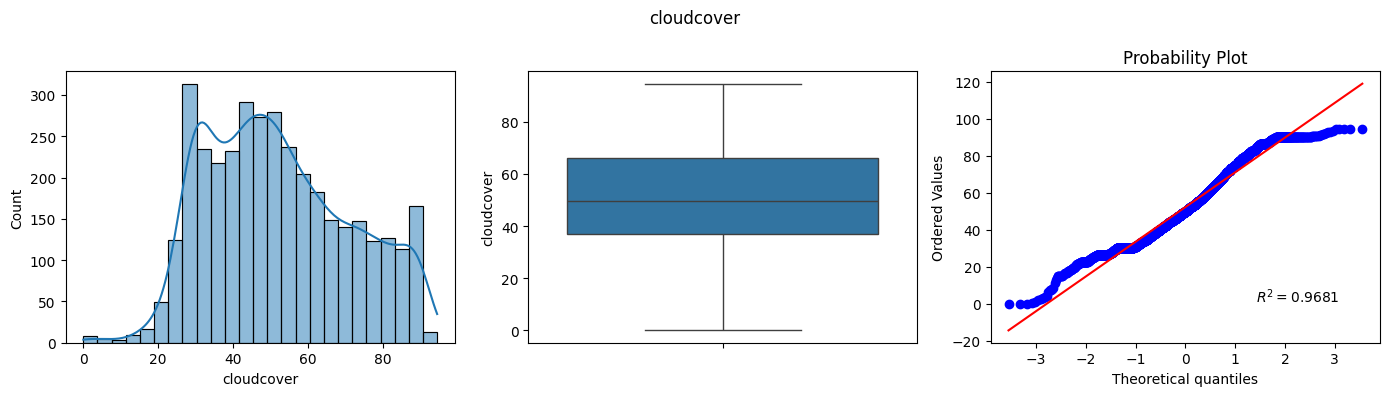

Skewness de visibility: 0.3596
Kurtosis de visibility: 9.6757


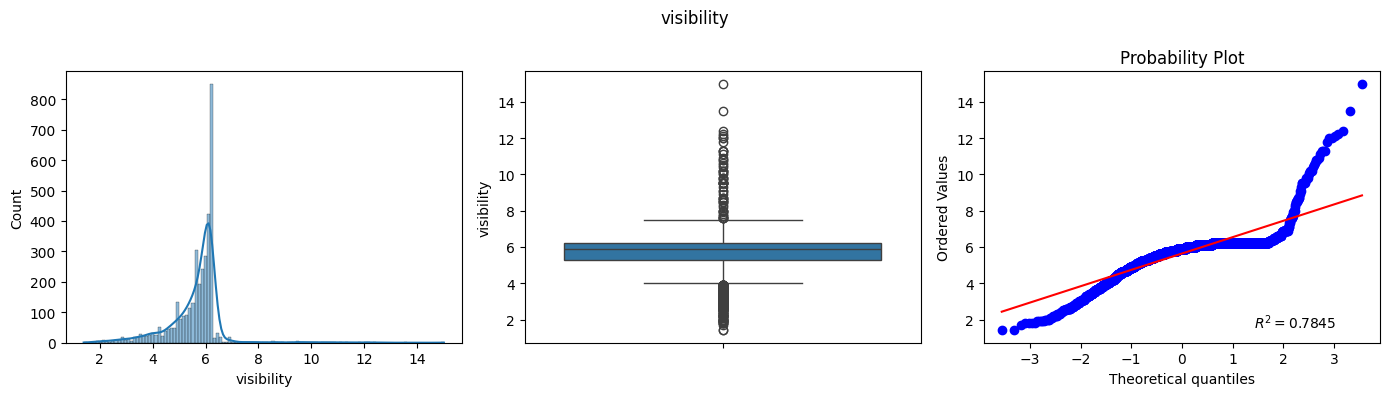

Skewness de solarradiation: -1.7491
Kurtosis de solarradiation: 4.9334


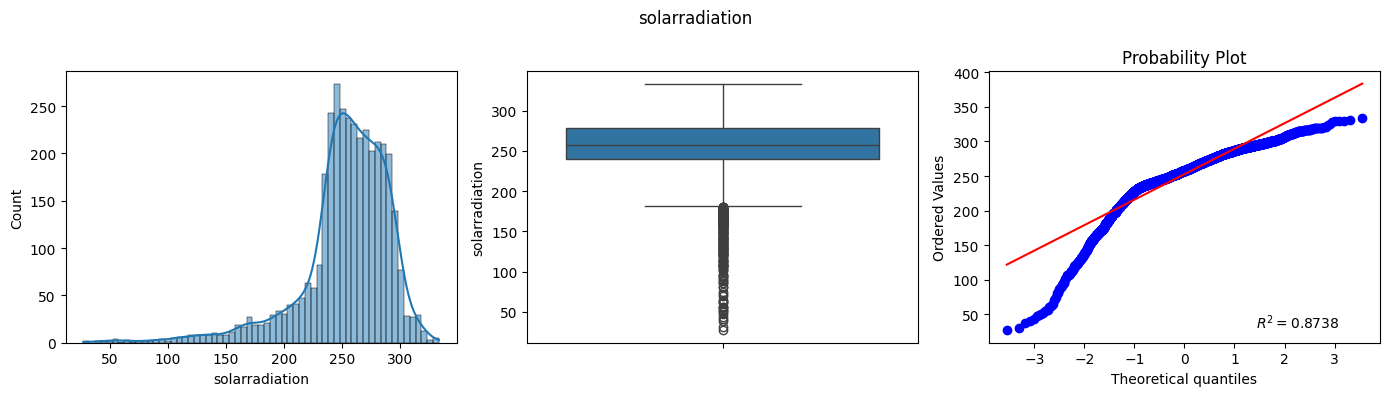

Skewness de solarenergy: -1.7576
Kurtosis de solarenergy: 4.9581


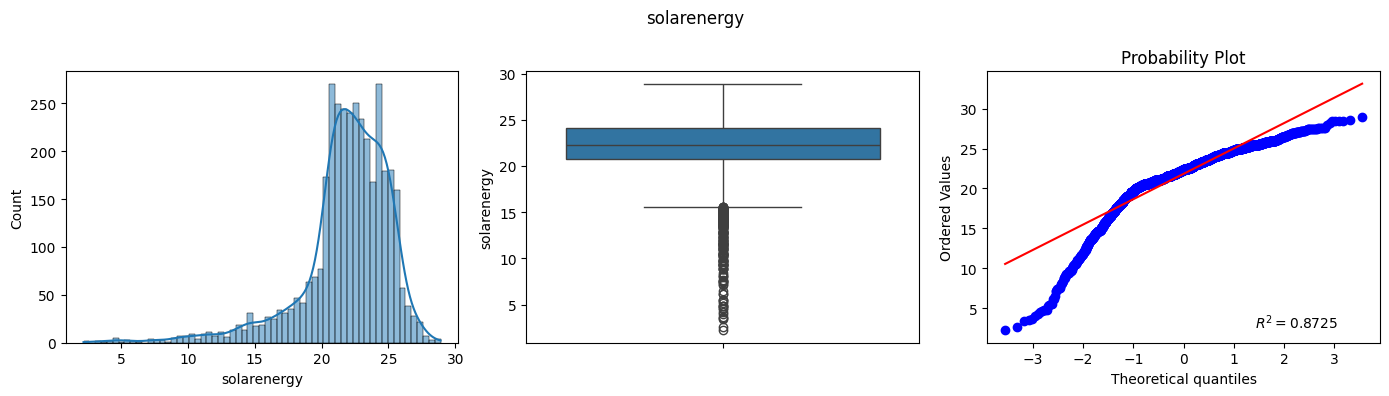

Skewness de uvindex: -2.0519
Kurtosis de uvindex: 6.4973


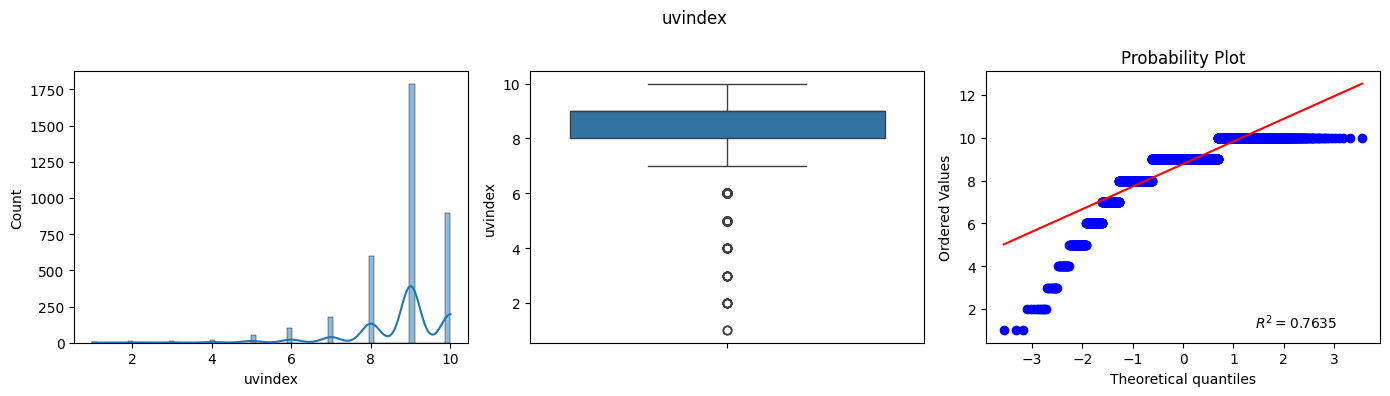

Skewness de severerisk: 1.6463
Kurtosis de severerisk: 2.7639


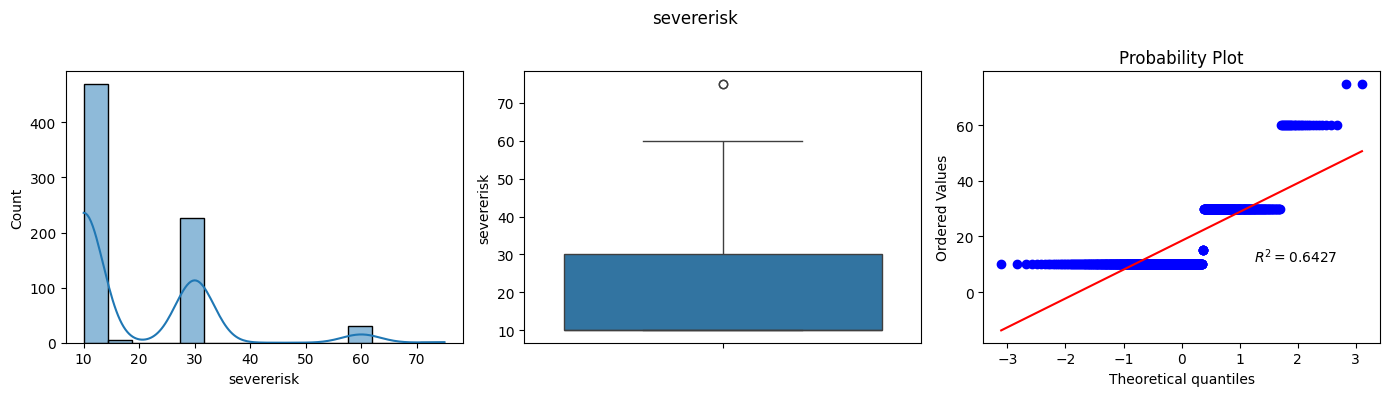

Skewness de moonphase: -0.0026
Kurtosis de moonphase: -1.1990


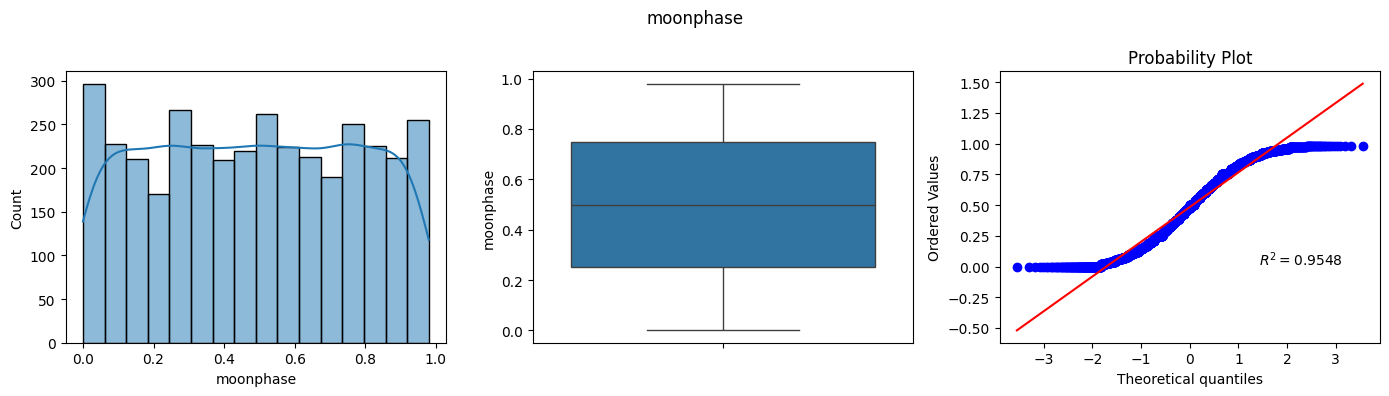

In [11]:
# Distribution et statistiques des variables numériques
numeric_cols = df.select_dtypes(np.number).columns.tolist()
for col in numeric_cols:
    plt.figure(figsize=(14, 4))
    print(f"Skewness de {col}: {df[col].skew():.4f}")
    print(f"Kurtosis de {col}: {df[col].kurtosis():.4f}")
    plt.subplot(131); sns.histplot(df[col], kde=True)
    plt.subplot(132); sns.boxplot(y=df[col])
    plt.subplot(133); probplot(df[col].dropna(), dist='norm', rvalue=True, plot=plt)
    plt.suptitle(col)
    plt.tight_layout()
    plt.show()
    plt.close('all')
    gc.collect()

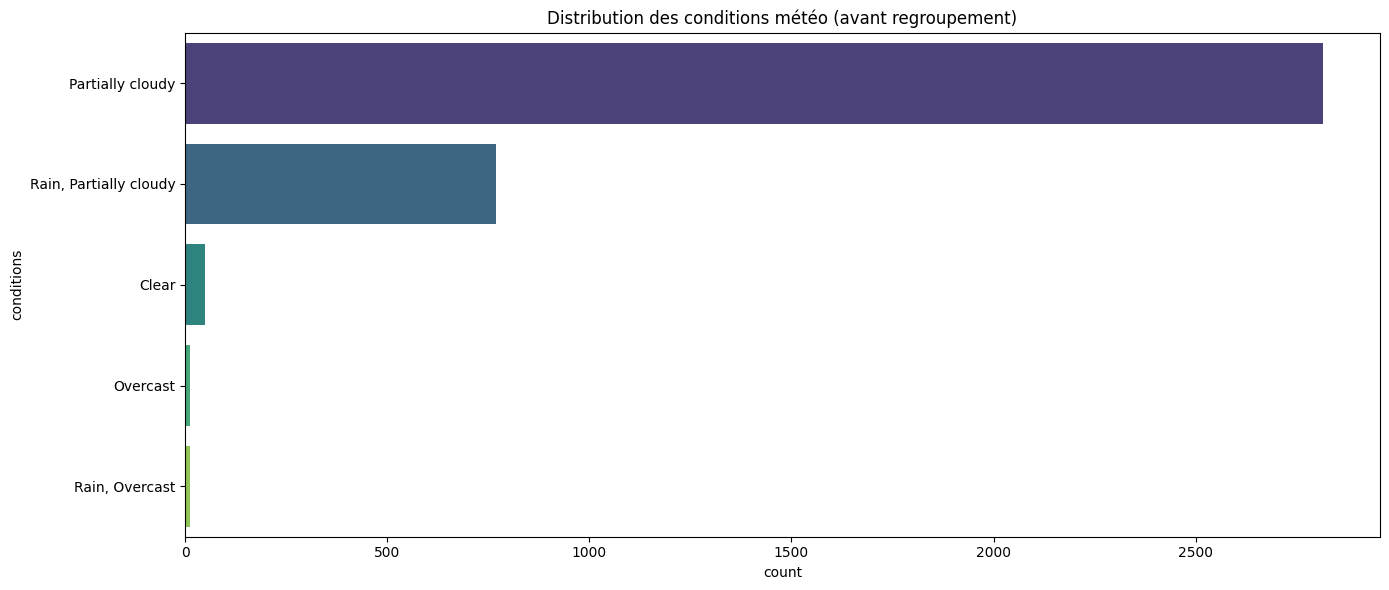


Nombre de classes uniques : 5
conditions
Partially cloudy          2815
Rain, Partially cloudy     770
Clear                       49
Overcast                    12
Rain, Overcast              12
Name: count, dtype: int64


In [12]:
# Distribution de la variable cible 'conditions'
plt.figure(figsize=(14, 6))
sns.countplot(y=df['conditions'], order=df['conditions'].value_counts().index, palette='viridis')
plt.title('Distribution des conditions météo (avant regroupement)')
plt.tight_layout()
plt.show()
plt.close('all')
gc.collect()

print(f"\nNombre de classes uniques : {df['conditions'].nunique()}")
print(df['conditions'].value_counts())

## Préparation de la variable cible

Regroupement des conditions météo en catégories principales.

In [13]:
# Copie de travail
df_clean = df.copy()

# ---- Regroupement des conditions en 8 catégories -------------------------
conditions_map = {
    'Clear':           ['Clear'],
    'Partially cloudy':['Partially cloudy'],
    'Overcast':        ['Overcast'],
    'Rain':            ['Rain', 'Rain, Overcast', 'Rain, Partially cloudy',
                        'Light Rain', 'Heavy Rain'],
    'Snow':            ['Snow', 'Snow, Overcast', 'Snow, Partially cloudy',
                        'Blowing Snow', 'Light Snow', 'Heavy Snow'],
    'Fog':             ['Fog', 'Fog, Overcast', 'Fog, Partially cloudy', 'Mist',
                        'Haze'],
    'Thunderstorm':    ['Thunderstorm', 'Thunderstorms', 'Thunder',
                        'Rain, Thunderstorms'],
    'Drizzle':         ['Drizzle', 'Drizzle, Overcast', 'Drizzle, Partially cloudy'],
}

# Construction du dictionnaire inverse value -> category
reverse_map = {v: k for k, vals in conditions_map.items() for v in vals}

# Application : les valeurs non mappées conservent leur valeur d'origine
df_clean['weather_label'] = df_clean['conditions'].map(reverse_map).fillna(df_clean['conditions'])

# Optionnel : supprimer les classes avec très peu d'observations (<50)
class_counts = df_clean['weather_label'].value_counts()
rare_classes = class_counts[class_counts < 50].index
df_clean = df_clean[~df_clean['weather_label'].isin(rare_classes)]

print("Classes après regroupement :")
print(df_clean['weather_label'].value_counts())

Classes après regroupement :
weather_label
Partially cloudy    2815
Rain                 782
Name: count, dtype: int64


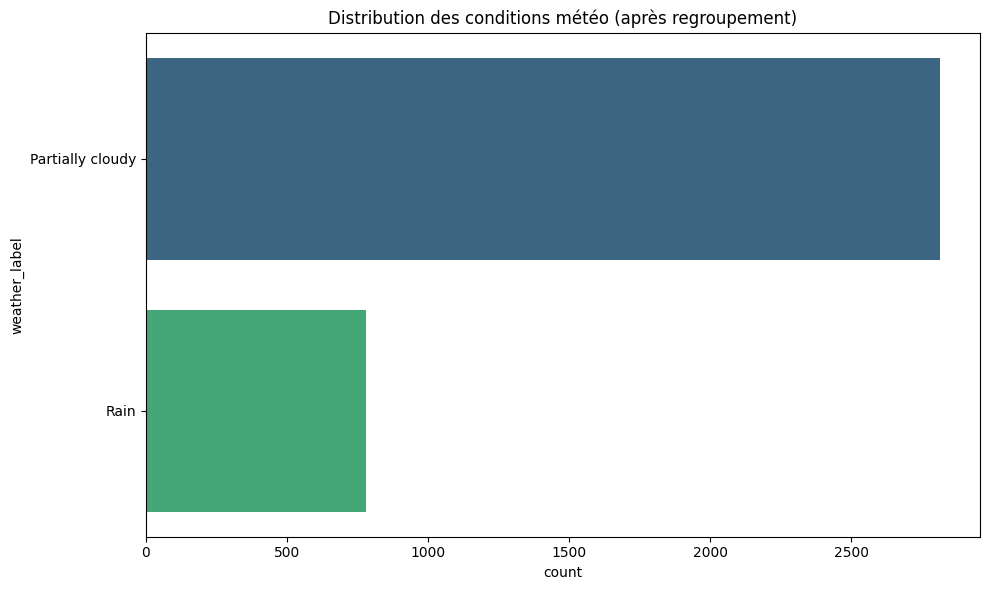

3036

In [14]:
plt.figure(figsize=(10, 6))
sns.countplot(y=df_clean['weather_label'],
              order=df_clean['weather_label'].value_counts().index,
              palette='viridis')
plt.title('Distribution des conditions météo (après regroupement)')
plt.tight_layout()
plt.show()
plt.close('all')
gc.collect()

## Feature Engineering

### Sélection explicite des features météo brutes

> **Philosophie** : on ne garde que les mesures physiques réelles — aucune colonne dérivée de la cible (`conditions`, `description`, `icon`, `preciptype`) pour éviter tout data leakage.

In [15]:
# ── Colonnes meteorologiques brutes uniquement (inspiré de votre pipeline ARIMA)
WEATHER_FEATURES = [
    'datetime',
    # Températures
    'tempmax', 'tempmin', 'temp',
    'feelslikemax', 'feelslikemin', 'feelslike',
    # Humidité / Point de rosée
    'dew', 'humidity',
    # Précipitations
    'precip', 'precipprob', 'precipcover',
    # Neige
    'snow', 'snowdepth',
    # Vent
    'windgust', 'windspeed', 'winddir',
    # Pression / Visibilité
    'sealevelpressure', 'visibility',
    # Rayonnement solaire
    'solarradiation', 'solarenergy', 'uvindex',
    # Risque sévère
    'severerisk',
    # Lever/Coucher du soleil (durée du jour)
    'sunrise', 'sunset',
    # Cible
    'conditions'
]

# Ne garder que les colonnes disponibles dans le dataset
available = [c for c in WEATHER_FEATURES if c in df.columns]
missing   = [c for c in WEATHER_FEATURES if c not in df.columns]
if missing:
    print(f"⚠ Colonnes absentes (ignorées) : {missing}")

df_model = df[available].copy()
print(f"Shape : {df_model.shape}")
df_model.head()


Shape : (3658, 26)


,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,precip,...,winddir,sealevelpressure,visibility,solarradiation,solarenergy,uvindex,severerisk,sunrise,sunset,conditions
0,2015-01-01,86.0,60.2,72.7,82.7,60.2,71.9,22.7,16.3,0.0,...,35.4,1015.4,6.0,245.1,21.4,9.0,NaN,2015-01-01T06:27:13,2015-01-01T17:51:56,Partially cloudy
1,2015-01-02,86.0,65.9,74.4,82.6,65.9,73.6,25.4,16.3,0.0,...,51.2,1016.0,5.8,230.0,19.9,8.0,NaN,2015-01-02T06:27:36,2015-01-02T17:52:29,Partially cloudy
2,2015-01-03,86.0,62.6,73.9,82.6,62.6,73.2,23.3,15.6,0.0,...,57.5,1017.1,5.1,236.5,20.5,8.0,NaN,2015-01-03T06:27:58,2015-01-03T17:53:03,Partially cloudy
3,2015-01-04,82.8,62.6,72.8,80.2,62.6,72.3,23.5,16.0,0.0,...,52.8,1018.2,3.9,238.2,20.5,8.0,NaN,2015-01-04T06:28:19,2015-01-04T17:53:36,Partially cloudy
4,2015-01-05,84.3,59.0,71.9,81.3,59.0,71.4,25.8,18.4,0.0,...,55.5,1017.5,3.1,244.1,21.1,9.0,NaN,2015-01-05T06:28:40,2015-01-05T17:54:10,Partially cloudy


### Features temporelles — durée du jour & cycliques

> On encode Month/DayOfYear de façon **cyclique** (sin/cos) pour éviter la discontinuité décembre→janvier, et on calcule la **durée du jour** depuis sunrise/sunset plutôt que de les garder bruts.

In [16]:
# ── Datetime
df_model['datetime'] = pd.to_datetime(df_model['datetime'])
df_model = df_model.sort_values('datetime').reset_index(drop=True)

# ── Durée du jour (en heures) depuis sunrise / sunset
if 'sunrise' in df_model.columns and 'sunset' in df_model.columns:
    def daylight_hours(row):
        try:
            date_str = str(row['datetime'].date())
            sr = pd.to_datetime(date_str + ' ' + str(row['sunrise']).split('T')[-1][:8])
            ss = pd.to_datetime(date_str + ' ' + str(row['sunset']).split('T')[-1][:8])
            return (ss - sr).seconds / 3600
        except Exception:
            return np.nan
    df_model['daylight_hours'] = df_model.apply(daylight_hours, axis=1)
    # Imputer les NaN par la médiane
    df_model['daylight_hours'].fillna(df_model['daylight_hours'].median(), inplace=True)
    df_model.drop(columns=['sunrise', 'sunset'], inplace=True)
    print("✔ daylight_hours calculé")

# ── Encodage cyclique du mois et du jour de l'année
df_model['month']       = df_model['datetime'].dt.month
df_model['day_of_year'] = df_model['datetime'].dt.dayofyear

df_model['month_sin']  = np.sin(2 * np.pi * df_model['month']       / 12)
df_model['month_cos']  = np.cos(2 * np.pi * df_model['month']       / 12)
df_model['doy_sin']    = np.sin(2 * np.pi * df_model['day_of_year'] / 365)
df_model['doy_cos']    = np.cos(2 * np.pi * df_model['day_of_year'] / 365)

# ── Encodage cyclique de la direction du vent
if 'winddir' in df_model.columns:
    df_model['winddir_sin'] = np.sin(np.radians(df_model['winddir']))
    df_model['winddir_cos'] = np.cos(np.radians(df_model['winddir']))
    df_model.drop(columns=['winddir'], inplace=True)
    print("✔ winddir encodé en sin/cos")

# ── Supprimer datetime (plus besoin)
df_model.drop(columns=['datetime', 'month', 'day_of_year'], inplace=True)

print(f"Shape : {df_model.shape}")
df_model.head()


✔ daylight_hours calculé
✔ winddir encodé en sin/cos
Shape : (3658, 29)


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,precip,precipprob,...,uvindex,severerisk,conditions,daylight_hours,month_sin,month_cos,doy_sin,doy_cos,winddir_sin,winddir_cos
0,86.0,60.2,72.7,82.7,60.2,71.9,22.7,16.3,0.0,0,...,9.0,NaN,Partially cloudy,11.411944,0.5,0.866025,0.017213,0.999852,0.579281,0.815128
1,86.0,65.9,74.4,82.6,65.9,73.6,25.4,16.3,0.0,0,...,8.0,NaN,Partially cloudy,11.414722,0.5,0.866025,0.034422,0.999407,0.779338,0.626604
2,86.0,62.6,73.9,82.6,62.6,73.2,23.3,15.6,0.0,0,...,8.0,NaN,Partially cloudy,11.418056,0.5,0.866025,0.051620,0.998667,0.843391,0.537300
3,82.8,62.6,72.8,80.2,62.6,72.3,23.5,16.0,0.0,0,...,8.0,NaN,Partially cloudy,11.421389,0.5,0.866025,0.068802,0.997630,0.796530,0.604599
4,84.3,59.0,71.9,81.3,59.0,71.4,25.8,18.4,0.0,0,...,9.0,NaN,Partially cloudy,11.425000,0.5,0.866025,0.085965,0.996298,0.824126,0.566406


### Features dérivées météo (physiquement interprétables)

In [17]:
# Amplitude thermique
df_model['temp_range']      = df_model['tempmax'] - df_model['tempmin']
df_model['feelslike_range'] = df_model['feelslikemax'] - df_model['feelslikemin']
df_model['temp_feel_diff']  = df_model['temp'] - df_model['feelslike']

# Indicateurs binaires (physiquement motivés)
df_model['has_precip']    = (df_model['precip']    > 0).astype(int)
df_model['has_snow']      = (df_model['snow']      > 0).astype(int)
df_model['high_humidity'] = (df_model['humidity']  > 80).astype(int)
df_model['high_wind']     = (df_model['windspeed'] > 30).astype(int)
df_model['low_vis']       = (df_model['visibility'] < 5).astype(int)  # brouillard probable

print(f"Shape : {df_model.shape}")
print("Nouvelles colonnes :", ['temp_range','feelslike_range','temp_feel_diff',
                                'has_precip','has_snow','high_humidity','high_wind','low_vis'])


Shape : (3658, 37)
Nouvelles colonnes : ['temp_range', 'feelslike_range', 'temp_feel_diff', 'has_precip', 'has_snow', 'high_humidity', 'high_wind', 'low_vis']


### Regroupement de la variable cible `conditions`

In [18]:
# Afficher toutes les valeurs uniques avant regroupement
print("Valeurs uniques de 'conditions' :")
print(sorted(df_model['conditions'].unique()))


Valeurs uniques de 'conditions' :
['Clear', 'Overcast', 'Partially cloudy', 'Rain, Overcast', 'Rain, Partially cloudy']


In [19]:
# ── Mapping vers catégories principales
# Adapter selon les valeurs réelles affichées ci-dessus
CONDITIONS_MAP = {
    # Clear
    'Clear':                          'Clear',
    # Partiellement nuageux
    'Partially cloudy':               'Partly Cloudy',
    # Couvert
    'Overcast':                       'Overcast',
    # Pluie
    'Rain':                           'Rain',
    'Rain, Overcast':                 'Rain',
    'Rain, Partially cloudy':         'Rain',
    'Light Rain':                     'Rain',
    'Heavy Rain':                     'Rain',
    # Drizzle
    'Drizzle':                        'Drizzle',
    'Drizzle, Overcast':              'Drizzle',
    'Drizzle, Partially cloudy':      'Drizzle',
    # Neige
    'Snow':                           'Snow',
    'Snow, Overcast':                 'Snow',
    'Snow, Partially cloudy':         'Snow',
    'Blowing Snow':                   'Snow',
    # Brouillard / Brume
    'Fog':                            'Fog',
    'Fog, Overcast':                  'Fog',
    'Fog, Partially cloudy':          'Fog',
    'Mist':                           'Fog',
    # Orage
    'Thunderstorm':                   'Thunderstorm',
    'Thunderstorms':                  'Thunderstorm',
    'Rain, Thunderstorms':            'Thunderstorm',
    'Rain, Thunderstorms, Overcast':  'Thunderstorm',
}

df_model['weather_label'] = df_model['conditions'].map(CONDITIONS_MAP)

# Valeurs non mappées → garder telles quelles (pour ne rien perdre)
unmapped = df_model[df_model['weather_label'].isna()]['conditions'].unique()
if len(unmapped):
    print(f"⚠ {len(unmapped)} valeur(s) non mappée(s) → conservées :")
    print(unmapped)
    df_model['weather_label'].fillna(df_model['conditions'], inplace=True)

# Supprimer les classes avec trop peu d'observations
MIN_SAMPLES = 30
counts = df_model['weather_label'].value_counts()
rare   = counts[counts < MIN_SAMPLES].index
if len(rare):
    print(f"Classes supprimées (< {MIN_SAMPLES} obs) : {list(rare)}")
    df_model = df_model[~df_model['weather_label'].isin(rare)]

df_model.drop(columns=['conditions'], inplace=True)

print("\nDistribution finale :")
print(df_model['weather_label'].value_counts())


Classes supprimées (< 30 obs) : ['Overcast']

Distribution finale :
weather_label
Partly Cloudy    2815
Rain              782
Clear              49
Name: count, dtype: int64


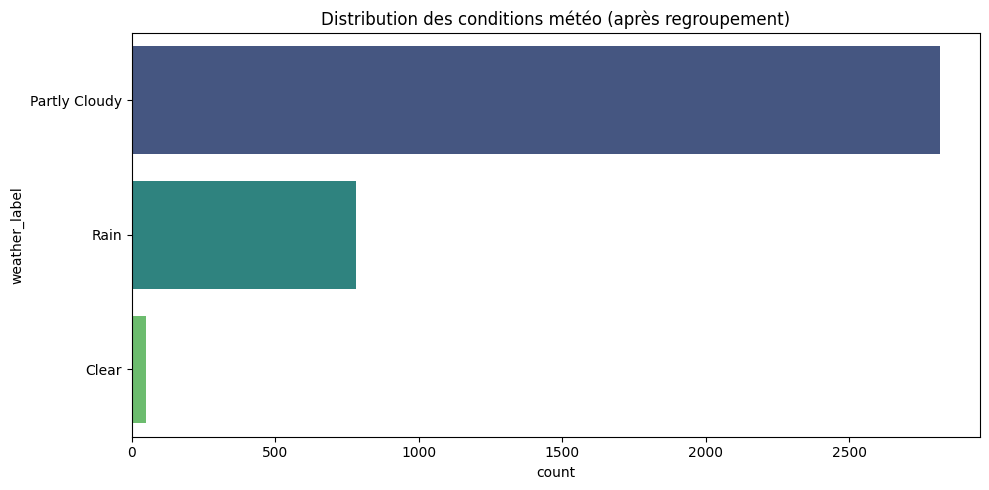

2516

In [20]:
plt.figure(figsize=(10, 5))
sns.countplot(y=df_model['weather_label'],
              order=df_model['weather_label'].value_counts().index,
              palette='viridis')
plt.title('Distribution des conditions météo (après regroupement)')
plt.tight_layout(); plt.show(); plt.close('all'); gc.collect()


### Matrice de corrélation

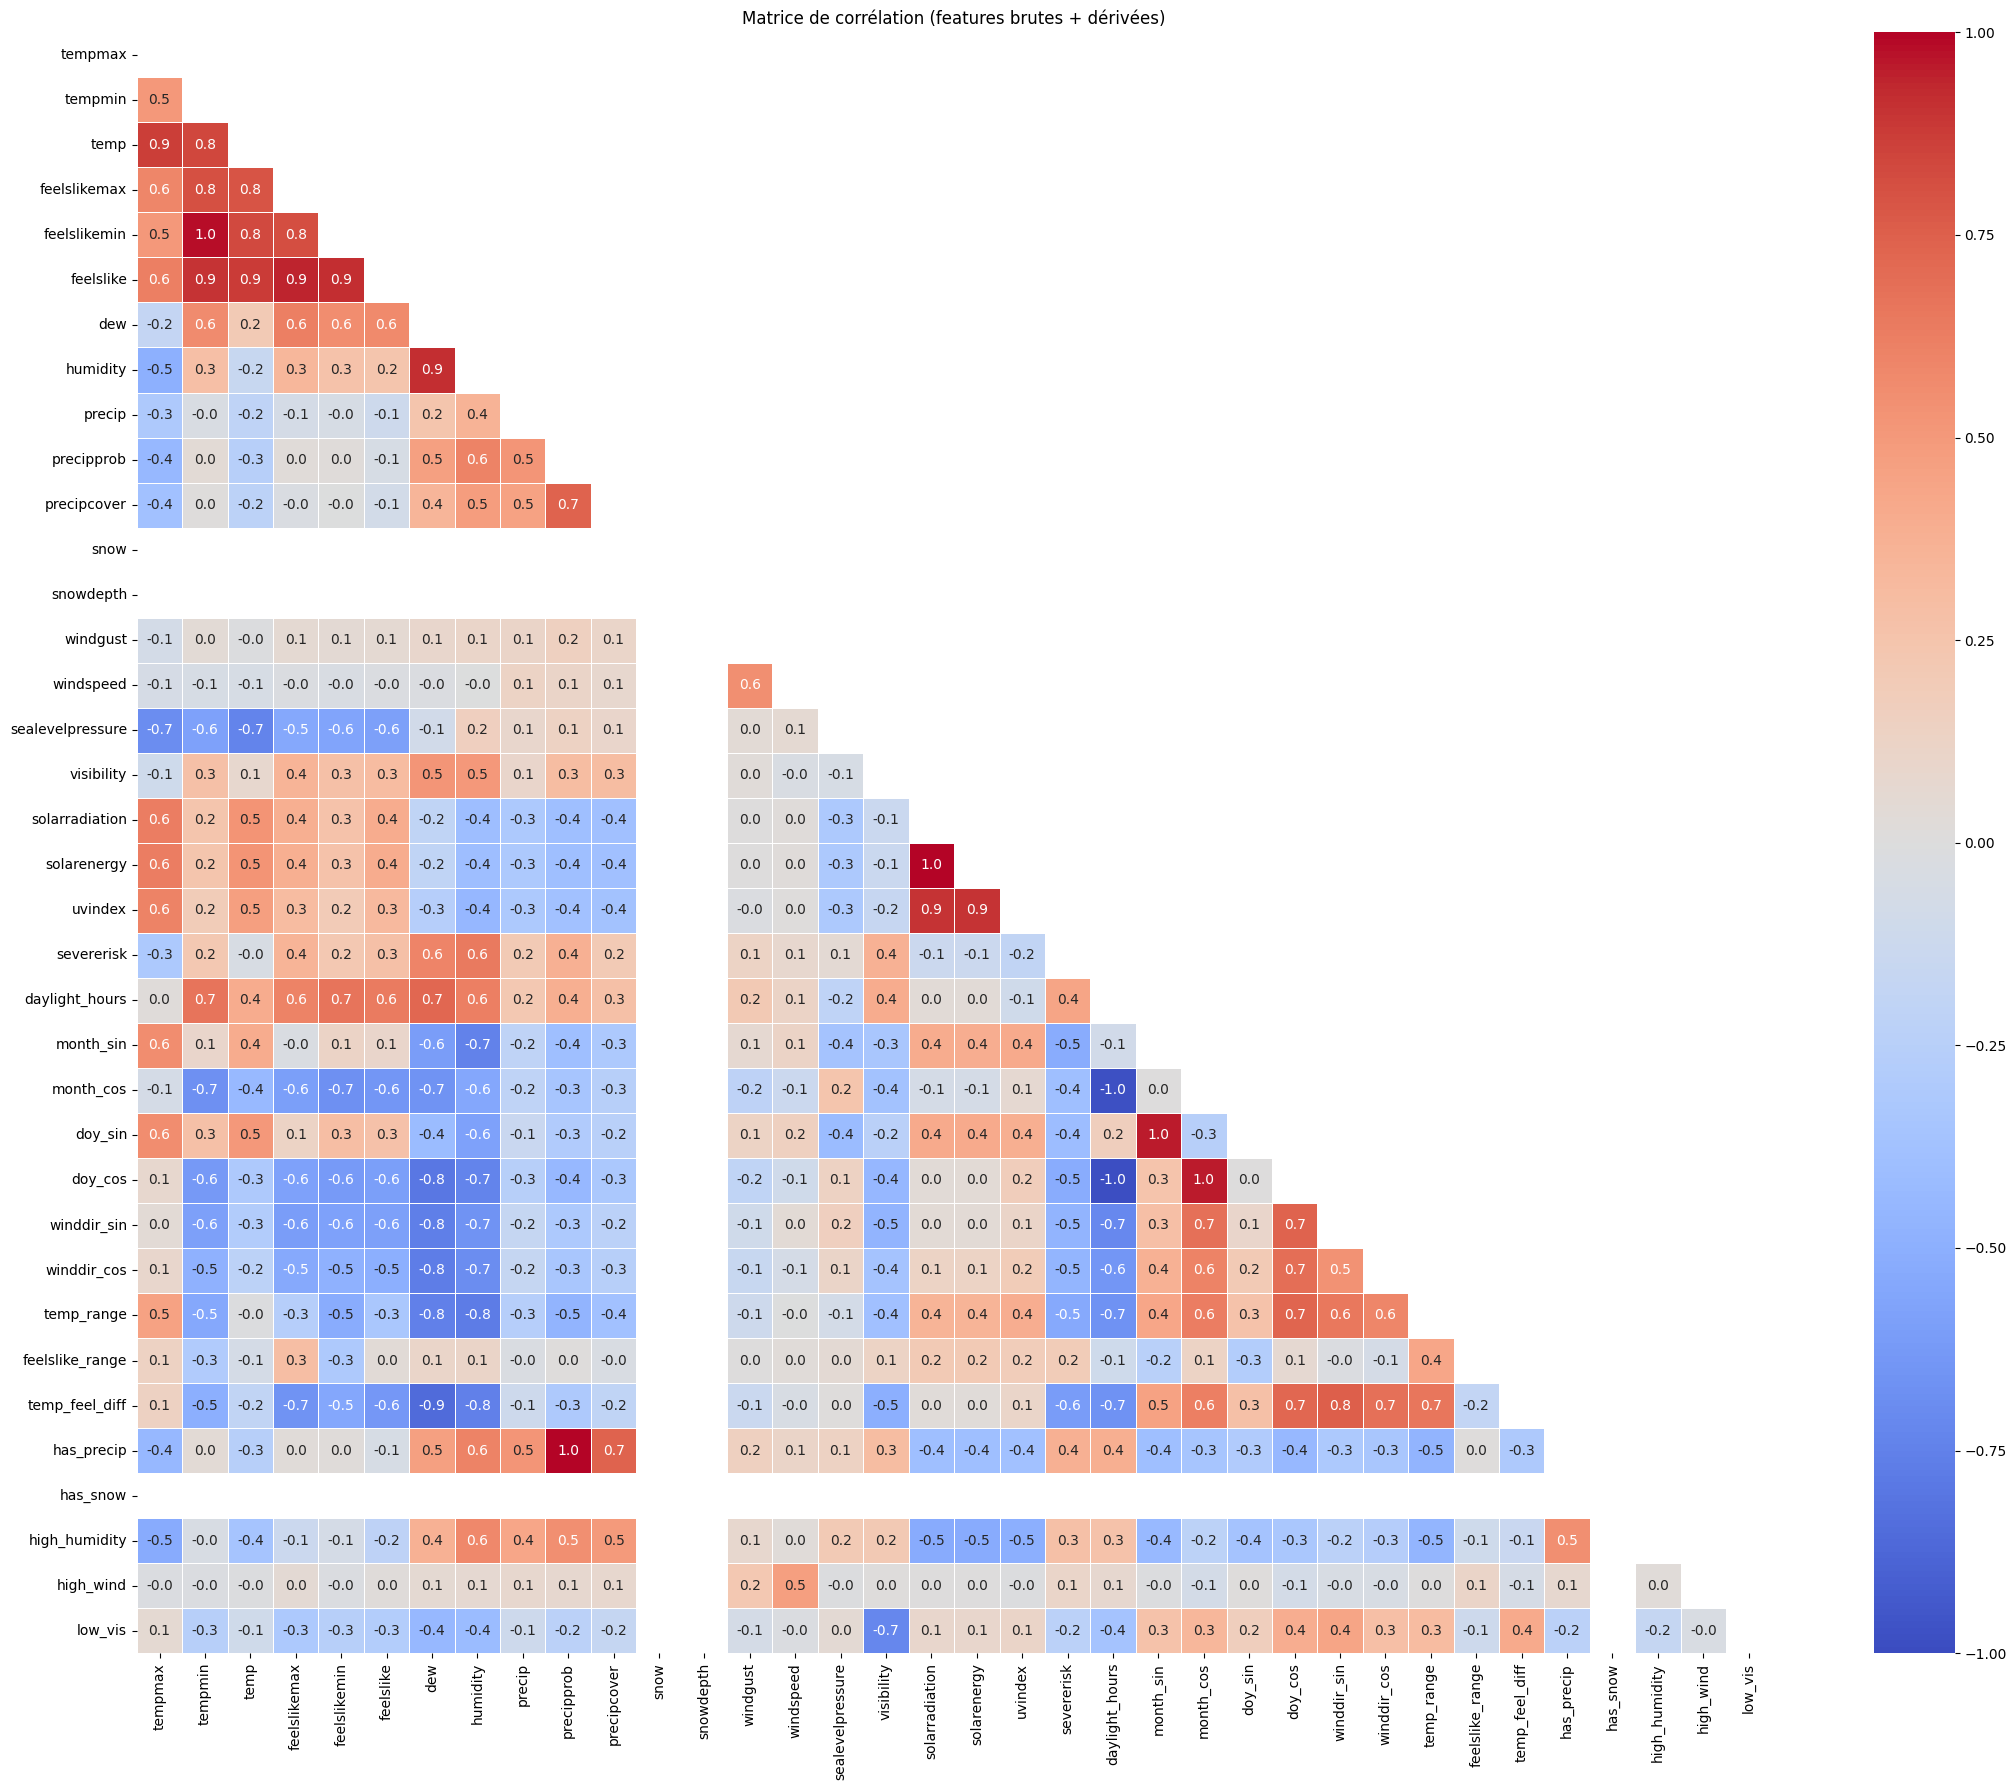

42863

In [21]:
plt.figure(figsize=(22, 18))
corr = df_model.select_dtypes(np.number).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.1f', cmap='coolwarm',
            vmin=-1, vmax=1, linewidths=0.4)
plt.title('Matrice de corrélation (features brutes + dérivées)')
plt.tight_layout(); plt.show(); plt.close('all'); gc.collect()


### Imputation des NaN & Winsorisation des outliers

In [22]:
# Imputation par médiane
num_cols = df_model.select_dtypes(np.number).columns
df_model[num_cols] = df_model[num_cols].fillna(df_model[num_cols].median())
print(f"NaN restants : {df_model.isna().sum().sum()}")

# Winsorisation (IQR) sur colonnes skewées
SKEWED = ['sealevelpressure', 'visibility', 'windspeed', 'windgust',
          'solarradiation', 'solarenergy', 'precip', 'precipprob',
          'precipcover', 'snowdepth']
SKEWED = [c for c in SKEWED if c in df_model.columns]

def winsorize(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return np.clip(series, q1 - 1.5 * iqr, q3 + 1.5 * iqr)

for col in SKEWED:
    df_model[col] = winsorize(df_model[col])
print(f"✔ Winsorisation appliquée sur : {SKEWED}")


NaN restants : 0
✔ Winsorisation appliquée sur : ['sealevelpressure', 'visibility', 'windspeed', 'windgust', 'solarradiation', 'solarenergy', 'precip', 'precipprob', 'precipcover', 'snowdepth']


## Préparation pour la modélisation

### Séparation X / y

In [23]:
X = df_model.drop('weather_label', axis=1)
y = df_model['weather_label']
print(f"X : {X.shape}   |   Classes : {y.nunique()}")
print(y.value_counts())


X : (3646, 36)   |   Classes : 3
weather_label
Partly Cloudy    2815
Rain              782
Clear              49
Name: count, dtype: int64


### Rééchantillonnage (BorderlineSMOTE)

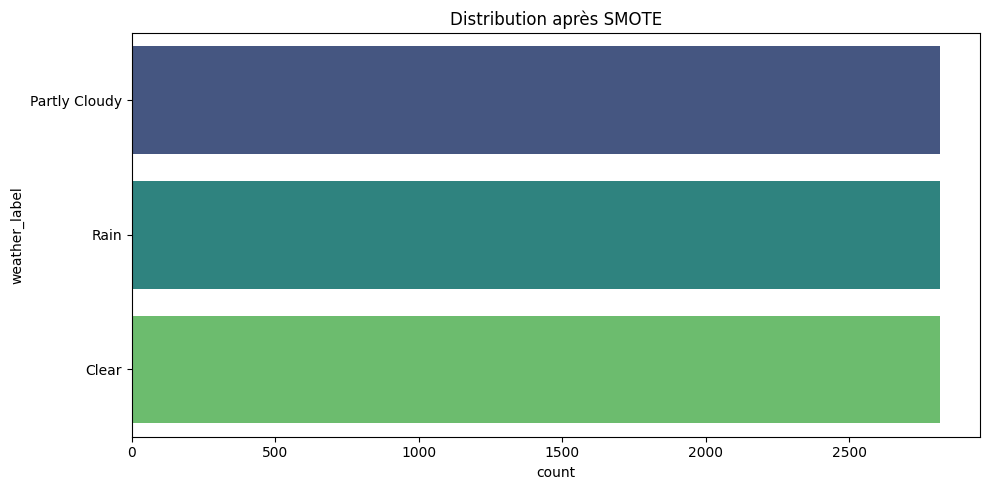

Counter({'Partly Cloudy': 2815, 'Rain': 2815, 'Clear': 2815})


In [24]:
borderline_smote = BorderlineSMOTE(random_state=42)
X_res, y_res = borderline_smote.fit_resample(X, y)

plt.figure(figsize=(10, 5))
sns.countplot(y=y_res, order=pd.Series(y_res).value_counts().index, palette='viridis')
plt.title('Distribution après SMOTE')
plt.tight_layout(); plt.show(); plt.close('all'); gc.collect()
print(Counter(y_res))


### Train / Test split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.3, random_state=42, shuffle=True, stratify=y_res
)
print(f"Train : {X_train.shape}   Test : {X_test.shape}")


Train : (5911, 36)   Test : (2534, 36)


### Label Encoding

In [26]:
encoder = LabelEncoder()
y_train_enc = encoder.fit_transform(y_train)
y_test_enc  = encoder.transform(y_test)

label_mapping = {label: idx for idx, label in enumerate(encoder.classes_)}
print("Mapping :", label_mapping)


Mapping : {'Clear': 0, 'Partly Cloudy': 1, 'Rain': 2}


### Feature Selection (pipeline feature_engine + XGBoost importances)

In [27]:
feature_pipeline = Pipeline(steps=[
    ('constant',   DropConstantFeatures(tol=0.98)),
    ('correlated', DropCorrelatedFeatures(threshold=0.90)),
    ('duplicate',  DropDuplicateFeatures())
])

X_train_fs = feature_pipeline.fit_transform(X_train)
X_test_fs  = feature_pipeline.transform(X_test)
print(f"Après pipeline : {X_train_fs.shape}  →  {X_test_fs.shape}")


Après pipeline : (5911, 21)  →  (2534, 21)


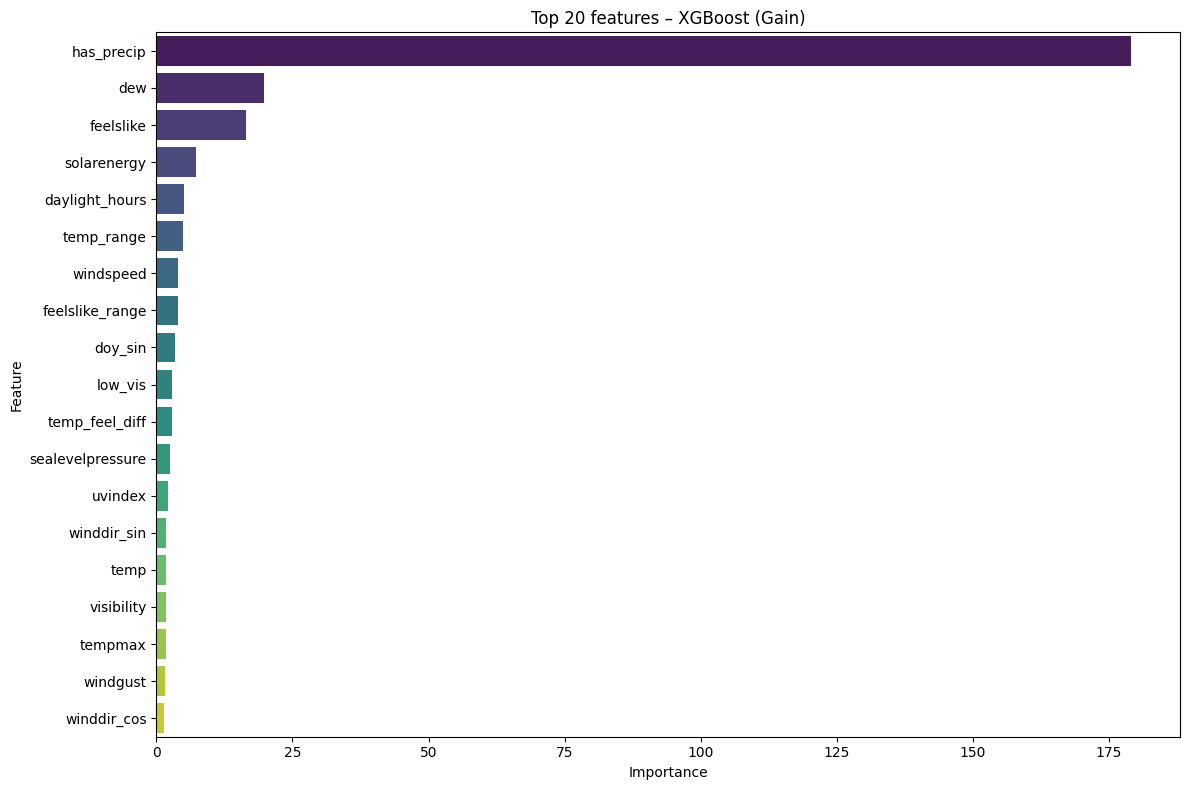

2697

In [28]:
# Importance via XGBoost
xgb_fs = XGBClassifier(random_state=42, eval_metric='mlogloss', n_estimators=100)
xgb_fs.fit(X_train_fs, y_train_enc)

feat_df = (
    pd.DataFrame.from_dict(
        xgb_fs.get_booster().get_score(importance_type='gain'),
        orient='index', columns=['Importance'])
    .sort_values('Importance', ascending=False)
    .reset_index().rename(columns={'index': 'Feature'})
)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feat_df.head(20), palette='viridis')
plt.title('Top 20 features – XGBoost (Gain)')
plt.tight_layout(); plt.show(); plt.close('all'); gc.collect()


In [29]:
# Garder les N features les plus importantes
# Ajuster N selon vos résultats (commencer avec 12-15)
N_FEATURES = 12
top_features = feat_df.head(N_FEATURES)['Feature'].tolist()
print(f"Top {N_FEATURES} features sélectionnées :\n", top_features)

final_X_train = X_train_fs[top_features]
final_X_test  = X_test_fs[top_features]


Top 12 features sélectionnées :
 ['has_precip', 'dew', 'feelslike', 'solarenergy', 'daylight_hours', 'temp_range', 'windspeed', 'feelslike_range', 'doy_sin', 'low_vis', 'temp_feel_diff', 'sealevelpressure']


### Normalisation (StandardScaler)

In [30]:
scaler   = StandardScaler()
features = final_X_train.columns.tolist()
final_X_train = pd.DataFrame(scaler.fit_transform(final_X_train), columns=features)
final_X_test  = pd.DataFrame(scaler.transform(final_X_test),      columns=features)
final_X_train.head()


,has_precip,dew,feelslike,solarenergy,daylight_hours,temp_range,windspeed,feelslike_range,doy_sin,low_vis,temp_feel_diff,sealevelpressure
0,-0.707017,-1.157141,-0.564168,0.651418,-0.618066,0.760656,0.478875,-0.353154,1.119639,2.375200,0.951632,0.220090
1,-0.707017,-1.807345,-0.627273,0.947464,-0.370381,0.518268,0.793170,-0.703832,1.284172,-0.421017,0.980856,-0.192980
2,1.414393,0.963355,0.859475,-0.646479,1.294160,-0.893693,-0.281458,0.293459,0.123560,-0.421017,-1.201929,-0.654788
3,-0.707017,-1.088712,-0.250206,0.947464,-0.360138,2.354624,0.299412,1.900294,1.287198,-0.421017,1.215774,-1.484522
4,-0.707017,0.995757,1.052739,0.693711,-0.223587,-0.427007,-0.448352,1.524719,-1.413713,-0.421017,-1.190851,0.440040


## Entraînement & Évaluation des modèles

In [31]:
models_list   = []
model_names   = []
accuracy_scores  = []
precision_scores = []
recall_scores    = []
f1_scores        = []

def train_and_evaluate(model, name=None):
    name = name or type(model).__name__
    model.fit(final_X_train, y_train_enc)
    y_pred = model.predict(final_X_test)
    print(f"\n{'='*60}")
    print(f"  {name}")
    print('='*60)
    print(classification_report(y_test_enc, y_pred, target_names=encoder.classes_))
    ConfusionMatrixDisplay.from_predictions(
        y_test_enc, y_pred, display_labels=encoder.classes_,
        xticks_rotation='vertical')
    plt.title(name)
    plt.tight_layout()
    plt.show()
    plt.close('all')

    acc  = accuracy_score(y_test_enc, y_pred)
    prec = precision_score(y_test_enc, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_test_enc, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_test_enc, y_pred, average='macro', zero_division=0)

    accuracy_scores.append(acc)
    precision_scores.append(prec)
    recall_scores.append(rec)
    f1_scores.append(f1)
    models_list.append(model)
    model_names.append(name)
    gc.collect()
    return model


  LogisticRegression
               precision    recall  f1-score   support

        Clear       0.76      0.94      0.84       844
Partly Cloudy       0.93      0.70      0.80       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.88      2534
    macro avg       0.90      0.88      0.88      2534
 weighted avg       0.90      0.88      0.88      2534



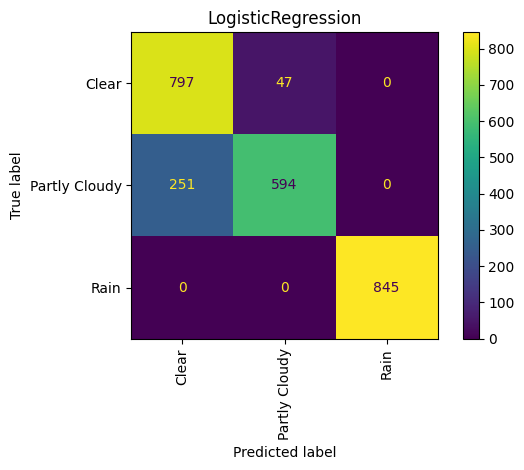

LogisticRegression(max_iter=1000)

In [32]:
train_and_evaluate(LogisticRegression(max_iter=1000))


  SGDClassifier
               precision    recall  f1-score   support

        Clear       0.76      0.95      0.84       844
Partly Cloudy       0.93      0.70      0.80       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.88      2534
    macro avg       0.90      0.88      0.88      2534
 weighted avg       0.90      0.88      0.88      2534



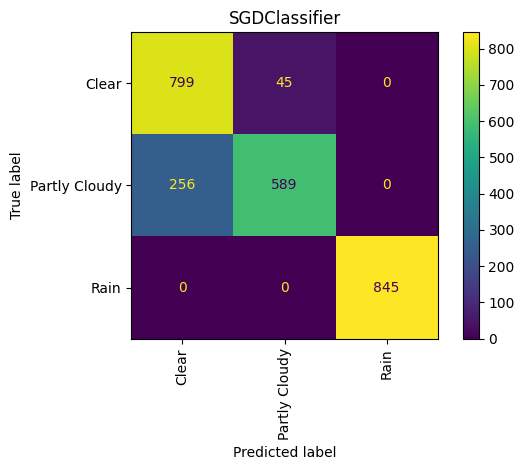

SGDClassifier()

In [33]:
train_and_evaluate(SGDClassifier())


  PassiveAggressiveClassifier
               precision    recall  f1-score   support

        Clear       0.78      0.72      0.75       844
Partly Cloudy       0.74      0.80      0.77       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.84      2534
    macro avg       0.84      0.84      0.84      2534
 weighted avg       0.84      0.84      0.84      2534



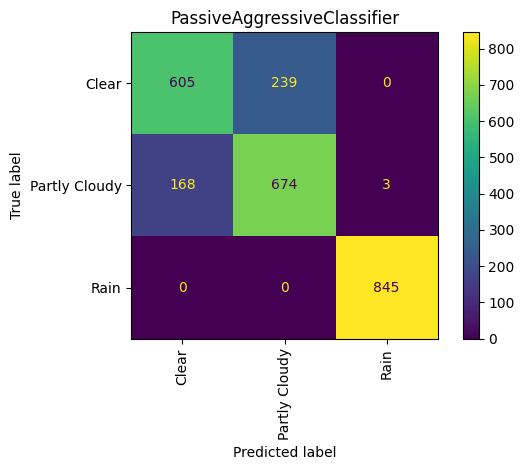

PassiveAggressiveClassifier()

In [34]:
train_and_evaluate(PassiveAggressiveClassifier())


  KNeighborsClassifier
               precision    recall  f1-score   support

        Clear       0.91      0.99      0.95       844
Partly Cloudy       0.99      0.91      0.95       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.97      2534
    macro avg       0.97      0.97      0.97      2534
 weighted avg       0.97      0.97      0.97      2534



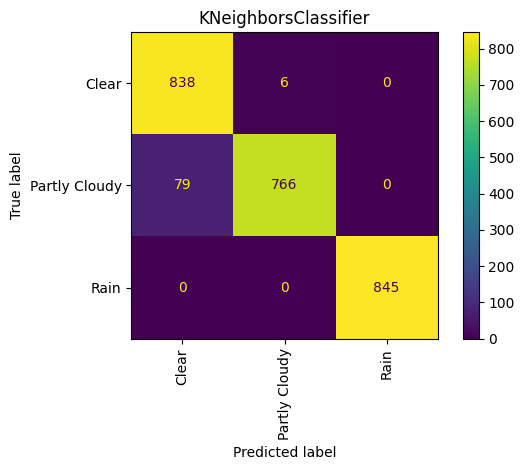

KNeighborsClassifier()

In [35]:
train_and_evaluate(KNeighborsClassifier())


  GaussianNB
               precision    recall  f1-score   support

        Clear       0.71      0.97      0.82       844
Partly Cloudy       0.96      0.61      0.74       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.86      2534
    macro avg       0.89      0.86      0.86      2534
 weighted avg       0.89      0.86      0.86      2534



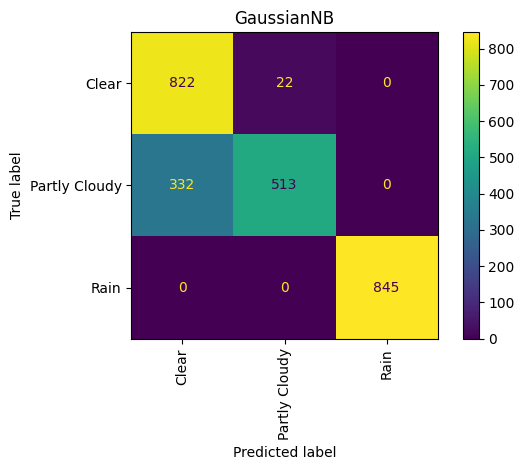

GaussianNB()

In [36]:
train_and_evaluate(GaussianNB())


  BernoulliNB
               precision    recall  f1-score   support

        Clear       0.71      0.96      0.82       844
Partly Cloudy       0.93      0.61      0.74       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.86      2534
    macro avg       0.88      0.86      0.85      2534
 weighted avg       0.88      0.86      0.85      2534



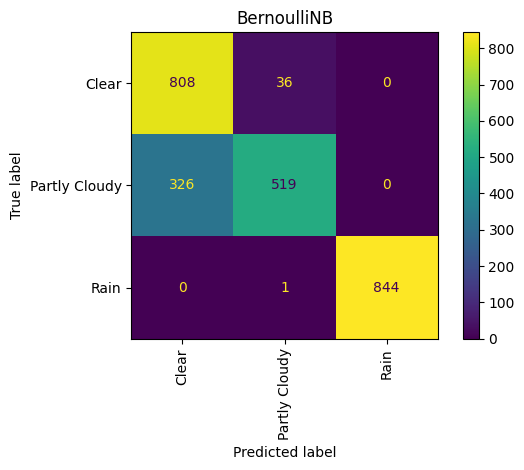

BernoulliNB()

In [37]:
train_and_evaluate(BernoulliNB())


  DecisionTreeClassifier
               precision    recall  f1-score   support

        Clear       0.96      0.98      0.97       844
Partly Cloudy       0.98      0.96      0.97       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.98      2534
    macro avg       0.98      0.98      0.98      2534
 weighted avg       0.98      0.98      0.98      2534



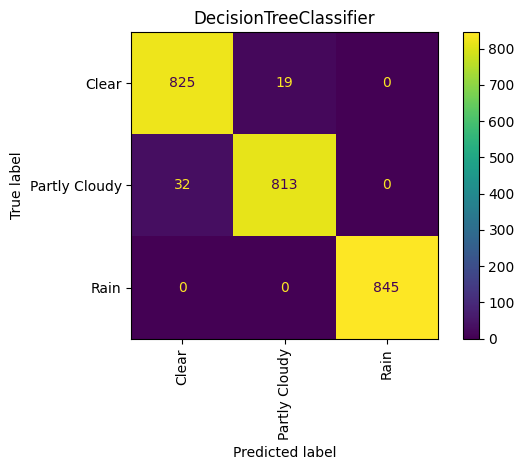

DecisionTreeClassifier()

In [38]:
train_and_evaluate(DecisionTreeClassifier())


  RandomForestClassifier
               precision    recall  f1-score   support

        Clear       0.98      0.99      0.99       844
Partly Cloudy       0.99      0.98      0.99       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.99      2534
    macro avg       0.99      0.99      0.99      2534
 weighted avg       0.99      0.99      0.99      2534



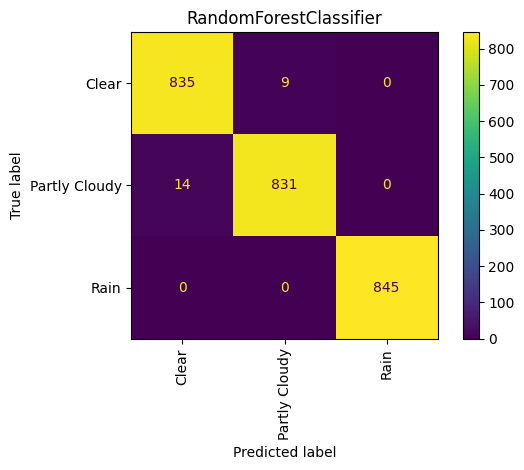

RandomForestClassifier(n_estimators=200, n_jobs=-1)

In [39]:
train_and_evaluate(RandomForestClassifier(n_estimators=200, n_jobs=-1))


  ExtraTreesClassifier
               precision    recall  f1-score   support

        Clear       0.99      0.99      0.99       844
Partly Cloudy       0.99      0.99      0.99       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.99      2534
    macro avg       0.99      0.99      0.99      2534
 weighted avg       0.99      0.99      0.99      2534



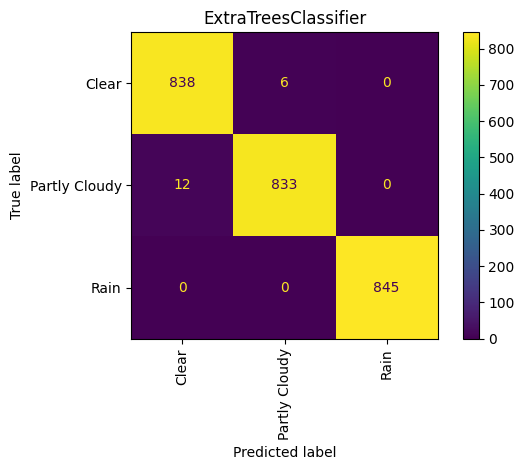

ExtraTreesClassifier(n_estimators=200, n_jobs=-1)

In [40]:
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, n_jobs=-1))


  GradientBoostingClassifier
               precision    recall  f1-score   support

        Clear       0.95      0.99      0.97       844
Partly Cloudy       0.99      0.95      0.97       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.98      2534
    macro avg       0.98      0.98      0.98      2534
 weighted avg       0.98      0.98      0.98      2534



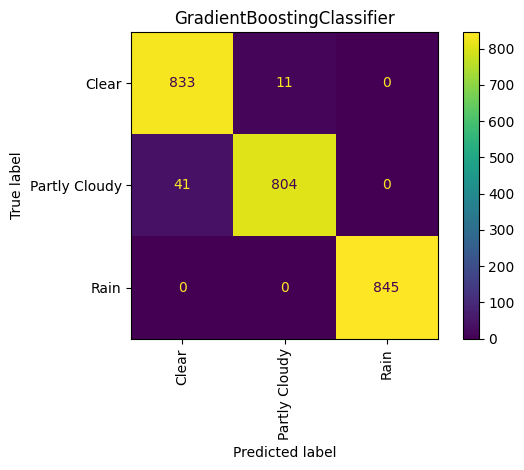

GradientBoostingClassifier()

In [41]:
train_and_evaluate(GradientBoostingClassifier())


  HistGradientBoostingClassifier
               precision    recall  f1-score   support

        Clear       0.98      0.99      0.99       844
Partly Cloudy       0.99      0.98      0.99       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.99      2534
    macro avg       0.99      0.99      0.99      2534
 weighted avg       0.99      0.99      0.99      2534



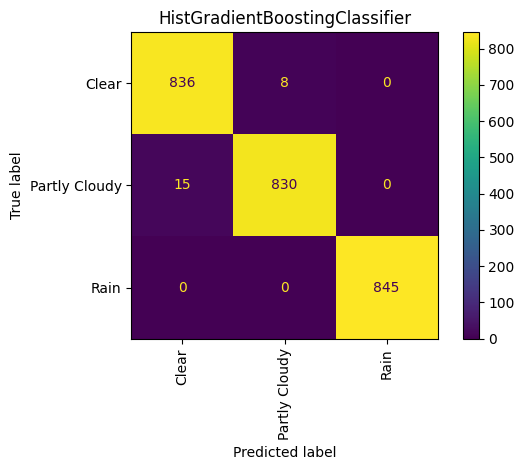

HistGradientBoostingClassifier()

In [42]:
train_and_evaluate(HistGradientBoostingClassifier())


  XGBClassifier
               precision    recall  f1-score   support

        Clear       0.98      0.99      0.98       844
Partly Cloudy       0.99      0.98      0.98       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.99      2534
    macro avg       0.99      0.99      0.99      2534
 weighted avg       0.99      0.99      0.99      2534



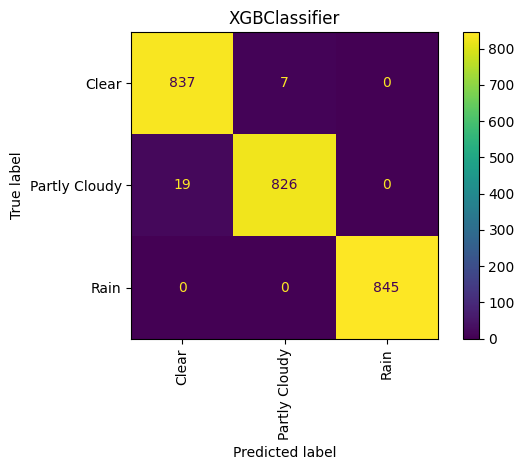

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [43]:
train_and_evaluate(XGBClassifier(eval_metric='mlogloss', use_label_encoder=False))


  LGBMClassifier
               precision    recall  f1-score   support

        Clear       0.99      0.99      0.99       844
Partly Cloudy       0.99      0.99      0.99       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.99      2534
    macro avg       0.99      0.99      0.99      2534
 weighted avg       0.99      0.99      0.99      2534



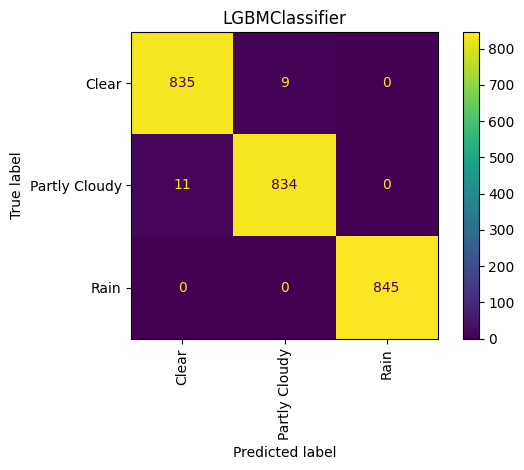

LGBMClassifier(verbose=-1)

In [44]:
train_and_evaluate(LGBMClassifier(verbose=-1))


  CatBoostClassifier
               precision    recall  f1-score   support

        Clear       0.98      0.99      0.99       844
Partly Cloudy       0.99      0.98      0.99       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.99      2534
    macro avg       0.99      0.99      0.99      2534
 weighted avg       0.99      0.99      0.99      2534



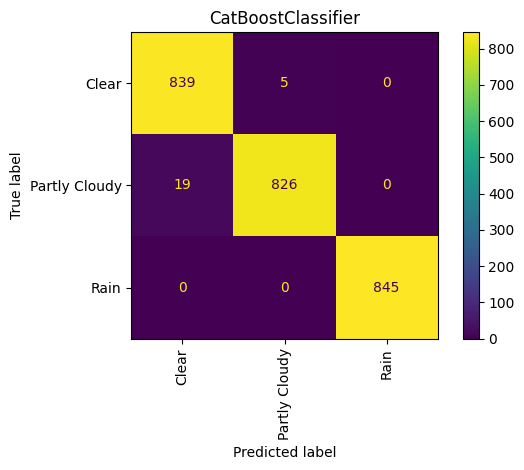

CatBoostClassifier(silent=True)

In [45]:
train_and_evaluate(CatBoostClassifier(silent=True))


  AdaBoostClassifier
               precision    recall  f1-score   support

        Clear       0.75      0.97      0.85       844
Partly Cloudy       0.96      0.68      0.80       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.88      2534
    macro avg       0.90      0.88      0.88      2534
 weighted avg       0.90      0.88      0.88      2534



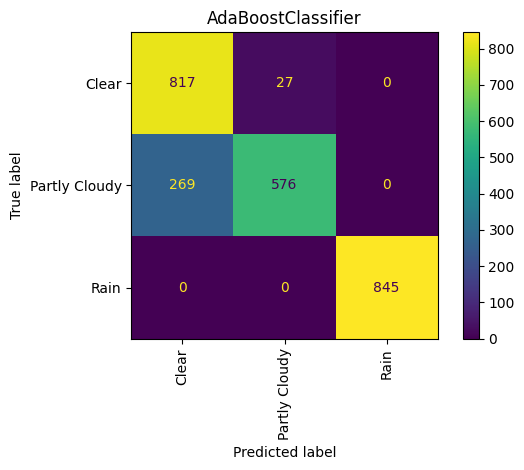

AdaBoostClassifier()

In [46]:
train_and_evaluate(AdaBoostClassifier())


  BaggingClassifier
               precision    recall  f1-score   support

        Clear       0.97      0.98      0.98       844
Partly Cloudy       0.98      0.97      0.98       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.99      2534
    macro avg       0.99      0.99      0.99      2534
 weighted avg       0.99      0.99      0.99      2534



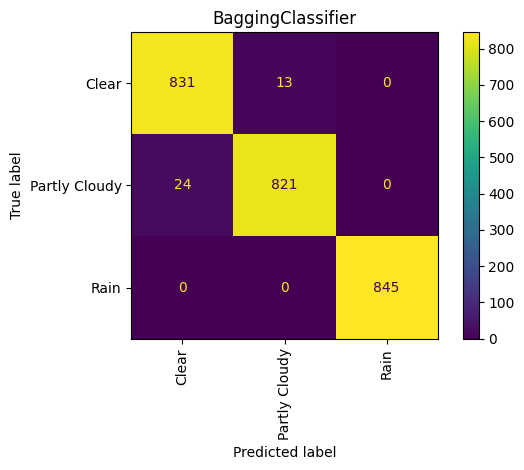

BaggingClassifier(n_jobs=-1)

In [47]:
train_and_evaluate(BaggingClassifier(n_jobs=-1))


  MLPClassifier
               precision    recall  f1-score   support

        Clear       0.97      0.99      0.98       844
Partly Cloudy       0.99      0.97      0.98       845
         Rain       1.00      1.00      1.00       845

     accuracy                           0.99      2534
    macro avg       0.99      0.99      0.99      2534
 weighted avg       0.99      0.99      0.99      2534



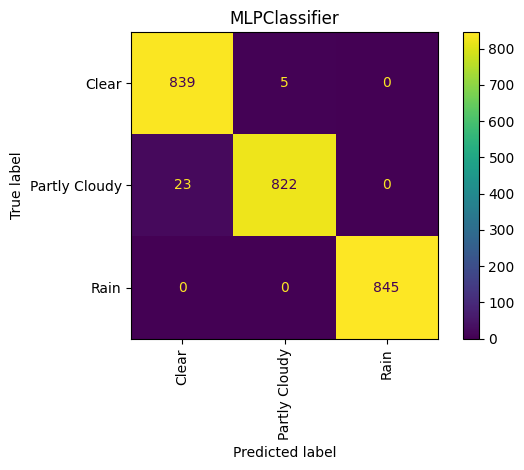

MLPClassifier(max_iter=500)

In [48]:
train_and_evaluate(MLPClassifier(max_iter=500))

### Comparaison des modèles

,Model,Accuracy,Precision,Recall,F1 Score
0,ExtraTreesClassifier,0.992897,0.992910,0.992897,0.992895
1,LGBMClassifier,0.992107,0.992107,0.992106,0.992106
2,RandomForestClassifier,0.990923,0.990932,0.990923,0.990922
3,HistGradientBoostingClassifier,0.990923,0.990942,0.990923,0.990922
4,CatBoostClassifier,0.990529,0.990613,0.990530,0.990526
5,XGBClassifier,0.989740,0.989800,0.989740,0.989737
6,MLPClassifier,0.988950,0.989091,0.988952,0.988947
7,BaggingClassifier,0.985399,0.985447,0.985398,0.985395
8,DecisionTreeClassifier,0.979874,0.979941,0.979873,0.979869
9,GradientBoostingClassifier,0.979479,0.979864,0.979482,0.979469


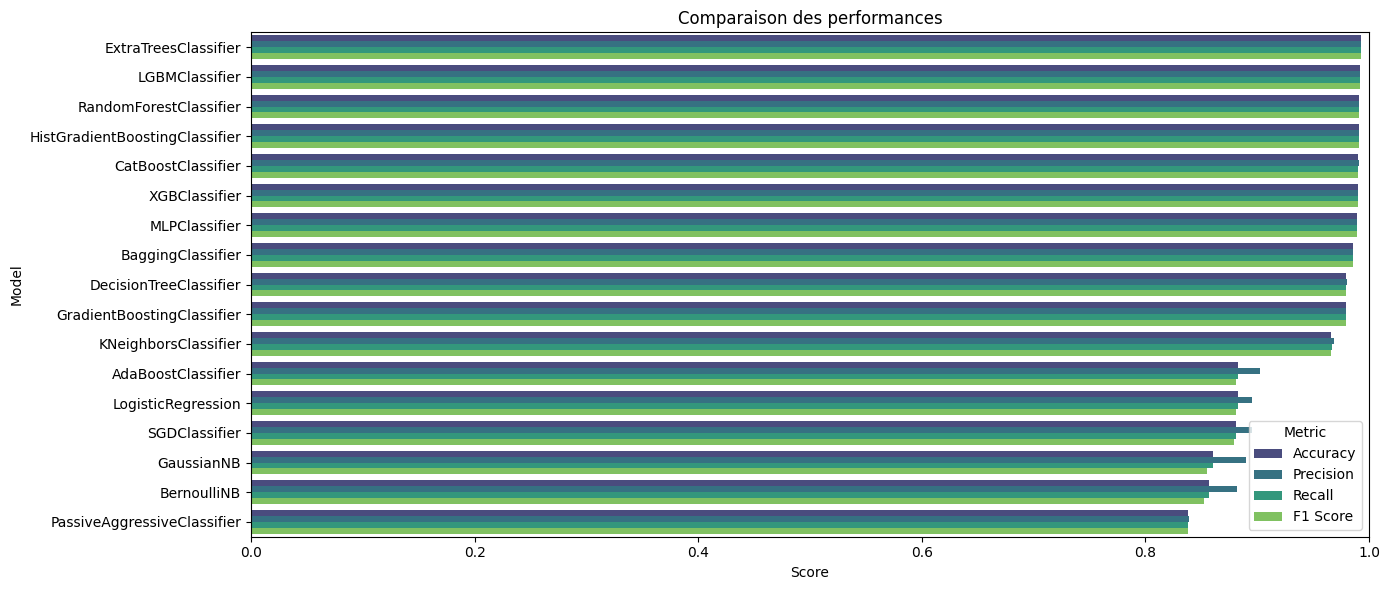

152

In [49]:
results_df = pd.DataFrame({
    'Model':     model_names,
    'Accuracy':  accuracy_scores,
    'Precision': precision_scores,
    'Recall':    recall_scores,
    'F1 Score':  f1_scores
}).sort_values('F1 Score', ascending=False).reset_index(drop=True)

display(results_df)

plt.figure(figsize=(14, 6))
results_melt = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')
sns.barplot(data=results_melt, x='Score', y='Model', hue='Metric', palette='viridis')
plt.title('Comparaison des performances')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()
plt.close('all')
gc.collect()

## Hyperparameter Tuning (meilleurs modèles)

In [50]:
# --- XGBoost ---
param_xgb = {
    'n_estimators':  [200, 500, 800],
    'max_depth':     [4, 6, 8],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample':     [0.7, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.9, 1.0]
}
grid_xgb = RandomizedSearchCV(
    XGBClassifier(eval_metric='mlogloss', use_label_encoder=False),
    param_xgb, n_iter=20, cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro', verbose=2, random_state=42, n_jobs=-1)
grid_xgb.fit(final_X_train, y_train_enc)
print("XGB best score :", grid_xgb.best_score_)
print("XGB best params:", grid_xgb.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
XGB best score : 0.9925674976553488
XGB best params: {'subsample': 0.9, 'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


In [52]:
# --- LightGBM ---
param_lgbm = {
    'n_estimators':  [200, 500, 800],
    'learning_rate': [0.05, 0.1, 0.2],
    'num_leaves':    [31, 63, 127],
    'max_depth':     [-1, 6, 10],
    'min_split_gain': [0.0, 0.5, 1.0]
}
grid_lgbm = RandomizedSearchCV(
    LGBMClassifier(verbose=-1),
    param_lgbm, n_iter=20, cv=5, scoring='f1_macro',
    verbose=2, random_state=42, n_jobs=-1)
grid_lgbm.fit(final_X_train, y_train_enc)
print("LGBM best score :", grid_lgbm.best_score_)
print("LGBM best params:", grid_lgbm.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
LGBM best score : 0.9922191330098963
LGBM best params: {'num_leaves': 127, 'n_estimators': 500, 'min_split_gain': 0.0, 'max_depth': 6, 'learning_rate': 0.1}


In [53]:
# --- Random Forest ---
param_rf = {
    'n_estimators': [200, 400, 800],
    'max_features': ['sqrt', 'log2'],
    'max_depth':    [None, 10, 20],
    'bootstrap':    [True, False],
    'class_weight': ['balanced', 'balanced_subsample']
}
grid_rf = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1),
    param_rf, n_iter=20, cv=5, scoring='f1_macro',
    verbose=2, random_state=42, n_jobs=-1)
grid_rf.fit(final_X_train, y_train_enc)
print("RF best score :", grid_rf.best_score_)
print("RF best params:", grid_rf.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
RF best score : 0.988837029721035
RF best params: {'n_estimators': 200, 'max_features': 'log2', 'max_depth': None, 'class_weight': 'balanced', 'bootstrap': False}


## Modèle Deep Learning (Keras)

In [54]:
n_classes = len(encoder.classes_)
n_features = final_X_train.shape[1]

dl_model = Sequential([
    Dense(64,  activation='relu', input_dim=n_features),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.25),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(n_classes, activation='softmax')
])

adam = Adam(learning_rate=1e-3, epsilon=1e-8, clipnorm=1.0)
dl_model.compile(loss='sparse_categorical_crossentropy', optimizer=adam, metrics=['accuracy'])
dl_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,459 (294.76 KB)

 Trainable params: 75,459 (294.76 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=50, mode='max', restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.1, patience=10, min_lr=1e-6, mode='max'),
    ModelCheckpoint('weather_predictor.keras', monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
]

history = dl_model.fit(
    final_X_train, y_train_enc,
    batch_size=32, epochs=500,
    callbacks=callbacks,
    validation_data=(final_X_test, y_test_enc),
    verbose=1
)

Epoch 1/500
175/185 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7560 - loss: 0.5226
Epoch 1: val_accuracy improved from None to 0.89740, saving model to weather_predictor.keras

Epoch 1: finished saving model to weather_predictor.keras
185/185 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8408 - loss: 0.3482 - val_accuracy: 0.8974 - val_loss: 0.2175 - learning_rate: 0.0010
Epoch 2/500
176/185 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9068 - loss: 0.2163
Epoch 2: val_accuracy improved from 0.89740 to 0.91831, saving model to weather_predictor.keras

Epoch 2: finished saving model to weather_predictor.keras
185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9114 - loss: 0.2103 - val_accuracy: 0.9183 - val_loss: 0.1904 - learning_rate: 0.0010
Epoch 3/500
181/185 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9375 - loss: 0.1623
Epoch 3: val_accuracy improved from 0.91831 to 0.94199, saving model to weather_predictor.keras

Epoch 3: finished saving model to weather_predictor.k

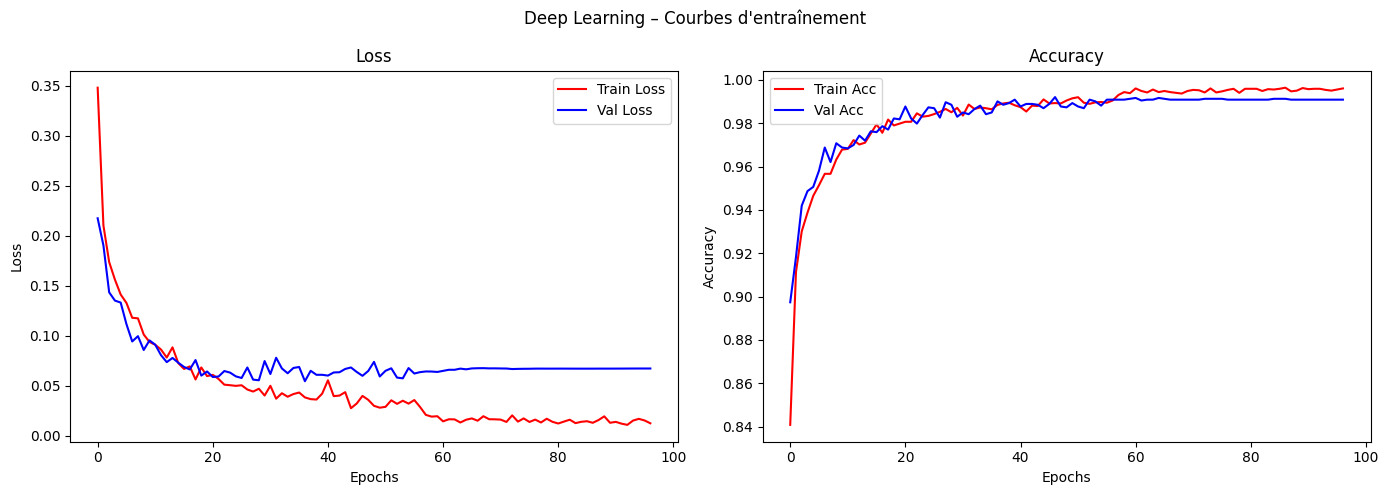

13104

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history['loss'], 'r', label='Train Loss')
axes[0].plot(history.history['val_loss'], 'b', label='Val Loss')
axes[0].set(title='Loss', xlabel='Epochs', ylabel='Loss'); axes[0].legend()
axes[1].plot(history.history['accuracy'], 'r', label='Train Acc')
axes[1].plot(history.history['val_accuracy'], 'b', label='Val Acc')
axes[1].set(title='Accuracy', xlabel='Epochs', ylabel='Accuracy'); axes[1].legend()
plt.suptitle('Deep Learning – Courbes d\'entraînement')
plt.tight_layout(); plt.show(); plt.close('all'); gc.collect()

## Sélection et sauvegarde du meilleur modèle

In [57]:
# Identifier le meilleur modèle sklearn par F1 macro
best_idx   = np.argmax(f1_scores)
best_model = models_list[best_idx]
best_name  = model_names[best_idx]
print(f"Meilleur modèle : {best_name}  (F1 = {f1_scores[best_idx]:.4f})")

Meilleur modèle : ExtraTreesClassifier  (F1 = 0.9929)


In [58]:
# Cross-validation finale
cv_scores = cross_val_score(
    best_model, final_X_test, y_test_enc,
    scoring='accuracy', cv=RepeatedKFold(n_repeats=3, n_splits=5), verbose=1, n_jobs=-1)
print(f"Score CV moyen ({best_name}) : {np.mean(cv_scores)*100:.2f}% ± {np.std(cv_scores)*100:.2f}%")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


Score CV moyen (ExtraTreesClassifier) : 98.58% ± 0.44%


[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    9.9s finished


In [59]:
# Sauvegarde
joblib.dump(best_model, 'best_model.pkl')
joblib.dump(scaler,     'scaler.pkl')
joblib.dump(encoder,    'label_encoder.pkl')
joblib.dump(feature_pipeline, 'feature_pipeline.pkl')
print("✔ Modèle, scaler, encodeur et pipeline sauvegardés.")

✔ Modèle, scaler, encodeur et pipeline sauvegardés.


### Plages de valeurs pour le formulaire de prédiction

In [60]:
for col in top_features:
    print(f"{col}:  min={X[col].min():.3f}  max={X[col].max():.3f}  mean={X[col].mean():.3f}")

print("\nClasses :", label_mapping)

has_precip:  min=0.000  max=1.000  mean=0.214
dew:  min=13.600  max=77.700  mean=57.008
feelslike:  min=67.900  max=105.900  mean=85.691
solarenergy:  min=15.600  max=28.900  mean=22.037
daylight_hours:  min=11.397  max=12.852  mean=12.130
temp_range:  min=5.000  max=39.000  mean=21.485
windspeed:  min=4.700  max=22.300  mean=13.137
feelslike_range:  min=5.000  max=42.400  mean=23.322
doy_sin:  min=-1.000  max=1.000  mean=-0.002
low_vis:  min=0.000  max=1.000  mean=0.174
temp_feel_diff:  min=-13.000  max=4.800  mean=-1.533
sealevelpressure:  min=1005.900  max=1017.100  mean=1011.476

Classes : {'Clear': 0, 'Partly Cloudy': 1, 'Rain': 2}
